# Adventure Works Cycles: limpieza y análisis descriptivo de ventas por internet

**Proyecto final · Introducción a la Ciencia de Datos**

**Integrantes:**

- Max Ayrton Vásquez Ruiz
- Luz Gabriela Cochachin Camacllanqui
- Brayan Luis Carpio Alegre
- Alexander Navas Rivadeneyra
- Danny Daniela Relaiza Bances

Notebook con todo el proceso: plan de trabajo, obtención y revisión de los datos desde SQL Server, calidad del dataset, limpieza, transformación, estadística descriptiva, visualización e interpretación de hallazgos.

Se ejecuta en orden, de arriba hacia abajo (*Run All*), en Jupyter local o en Google Colab.

## 0. Configuración

Librerías, rutas de entrada y salida, y estilo común de los gráficos.

Los datos se obtienen de la base **AdventureWorksDW2022** en SQL Server. Si existe el archivo `.env` con las credenciales (ver `.env.example`), la celda de la sección 2.2 vuelve a extraer las tablas; si no, usa las copias en CSV de `datos/SL/`. En Google Colab, si los CSV no están, la celda pide subirlos.

In [1]:
import os
import sys
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

EN_COLAB = "google.colab" in sys.modules

RAIZ = Path.cwd()
SL = RAIZ / "datos" / "SL"
CL = RAIZ / "datos" / "CL" / "ventas_CL.csv"
IMAGENES = RAIZ / "datos" / "imagenes"
REPORTE = RAIZ / "reporte" / "REPORTE_NO_CORREGIDOS.csv"
GRAFICOS = RAIZ / "graficos"

for carpeta in (SL, IMAGENES, CL.parent, REPORTE.parent, GRAFICOS):
    carpeta.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 3.1.1 | numpy 2.5.5 | seaborn 0.13.2


In [2]:
# Paleta fija: cada entidad conserva su color en todos los gráficos
TINTA, TINTA_2, TENUE = "#0b0b0b", "#52514e", "#898781"
GRILLA, FONDO, GRIS = "#e1e0d9", "#fcfcfb", "#c3c2b7"
AZUL, AZUL_CLARO, ROJO = "#2a78d6", "#86b6ef", "#e34948"

COLOR_CATEGORIA = {"Bicicletas": "#2a78d6", "Accesorios": "#eb6834", "Ropa": "#1baf7a"}
COLOR_PAIS = {"Estados Unidos": "#2a78d6", "Australia": "#eb6834", "Reino Unido": "#1baf7a",
              "Alemania": "#eda100", "Francia": "#e87ba4", "Canadá": "#8a63d2"}

SECUENCIAL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGENTE = LinearSegmentedColormap.from_list(
    "rojo_azul", ["#b52f2f", ROJO, "#f0efec", "#3987e5", "#184f95"])

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})


def guardar(fig, nombre):
    """Guarda el gráfico en graficos/ y lo muestra."""
    fig.savefig(GRAFICOS / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()


def millones(valor):
    return f"US$ {valor / 1e6:,.2f} M"

## 1. Plan de trabajo

### 1.1 Contexto y objetivo

**Adventure Works Cycles** es una empresa (ficticia, creada por Microsoft como base de ejemplo) que fabrica y vende bicicletas, accesorios y ropa de ciclismo. Además de vender a revendedores, vende **por internet a clientes finales de seis países**: Estados Unidos, Canadá, Australia, Reino Unido, Alemania y Francia. Su almacén de datos reúne las ventas, el catálogo de productos y el perfil de los clientes, pero no se sabe qué tan confiables son esos datos para tomar decisiones.

**Objetivo:** evaluar y asegurar la calidad de los datos de ventas por internet y obtener un análisis descriptivo que ayude a la gerencia a decidir en qué productos, mercados y clientes enfocarse.

**Preguntas de negocio y KPI**

| # | Pregunta | KPI |
|---|---|---|
| P1 | ¿Qué categorías y productos generan los ingresos y el margen? | Ingresos, margen bruto, participación %, margen % |
| P2 | ¿Cómo evolucionan las ventas en el tiempo y hay estacionalidad? | Ingresos y pedidos mensuales, variación anual |
| P3 | ¿En qué países están los clientes y cuánto aporta cada uno? | Ingresos, clientes e ingreso por cliente por país |
| P4 | ¿Qué perfil de cliente gasta más y quién compra bicicletas? | Gasto por cliente y % que compra bicicleta según ingreso, autos, hijos y edad |
| P5 | ¿Por qué compran los clientes y funcionan las promociones? | % de pedidos por razón de compra y por promoción |
| P6 | ¿Cuánto aporta cada grupo de clientes y cuántos vuelven a comprar? | % de ingresos por segmento, % de clientes recurrentes |

### 1.2 Ciclo de vida: CRISP-DM

Se usa **CRISP-DM** porque ordena el trabajo desde la pregunta de negocio hasta la comunicación de resultados y permite volver a fases anteriores (por ejemplo, de la validación a la limpieza). Como el objetivo es descriptivo, la fase de modelado corresponde al análisis estadístico; un modelo predictivo queda como siguiente etapa.

| Fase CRISP-DM | Flujo del científico de datos | Qué se hace con este dataset | Sección | Responsable | Resultado esperado |
|---|---|---|---|---|---|
| 1. Comprensión del negocio | Definición del problema | Preguntas P1–P6 y KPI | 1 | Líder del proyecto | Alcance y KPI acordados |
| 2. Comprensión de los datos | Obtención | Extraer 11 tablas de SQL Server con Python, describir las variables, clasificar los tipos de datos (incluido XML, texto libre e imágenes) y medir la calidad con reglas | 2 | Ingeniero de datos, Analista de datos | Copia SL en CSV, diccionario de datos y diagnóstico de calidad |
| 3. Preparación de los datos | Preparación | Quitar columnas sin información, unificar formatos (teléfonos, códigos postales, tallas), resolver vacíos disfrazados, integrar las tablas del esquema estrella, convertir tipos y crear variables derivadas | 3 y 4 | Ingeniero de datos, Científico de datos | `ventas_CL.csv`, reporte de lo no corregido y tabla de clientes |
| 4. Modelado | Análisis | Estadística univariada y multivariada, agrupaciones, correlaciones y segmentación de clientes por gasto | 5 | Científico de datos | Tablas de resumen que responden P1–P6 |
| 5. Evaluación | Validación | Volver a aplicar las reglas a los datos limpios y revisar que los resultados respondan las preguntas | 3.8 y 7 | Científico de datos, Líder del proyecto | Datos validados y hallazgos revisados |
| 6. Despliegue | Visualización e interpretación | Gráficos, interpretación y recomendaciones para la gerencia | 6 y 7 | Analista de datos, Líder del proyecto | Gráficos, informe y exposición |

### 1.3 Roles del equipo

| Rol | Responsabilidades |
|---|---|
| **Líder del proyecto** | Acuerda las preguntas con la gerencia, coordina las fases, revisa que los hallazgos respondan P1–P6 y presenta los resultados. |
| **Ingeniero de datos** | Restaura la base en SQL Server, gestiona el acceso seguro (`.env`), extrae las tablas, define las reglas de calidad y ejecuta la limpieza y el reporte de lo no corregido. |
| **Científico de datos** | Integra las tablas, diseña las transformaciones y variables derivadas, calcula la estadística descriptiva, las correlaciones y la segmentación, y valida los datos limpios. |
| **Analista de datos** | Elabora las visualizaciones, interpreta los patrones y redacta las recomendaciones para el negocio. |

### 1.4 Proyección de resultados

Al cerrar el ciclo se espera tener: (1) un dataset de ventas integrado, con formatos únicos y validado contra las mismas reglas del diagnóstico; (2) un reporte de los datos que no se pueden corregir sin inventarlos, para que el área de sistemas los corrija en el origen; (3) KPI por categoría, mes, país, perfil y segmento de clientes; y (4) recomendaciones concretas para la gestión comercial, por ejemplo qué mercados priorizar, a qué perfil de cliente dirigir las campañas de bicicletas y cómo aumentar la recompra.

## 2. Revisión del dataset

### 2.1 Fuente y contexto

La fuente es **AdventureWorksDW2022**, el almacén de datos de ejemplo que Microsoft publica para SQL Server. Se descargó como respaldo (`AdventureWorksDW2022.bak`) y se restauró en **SQL Server 2022** local. Es un **esquema estrella**: tablas de hechos con las transacciones (`Fact…`) y tablas de dimensiones con sus atributos (`Dim…`).

El proyecto se enfoca en las **ventas por internet a clientes finales** (`FactInternetSales`), porque es el único canal que registra el perfil de quien compra (edad, ingreso, hijos, autos, educación). Se usan 11 tablas:

| Tabla en SQL Server | Archivo en `datos/SL/` | Tipo | Contenido |
|---|---|---|---|
| `FactInternetSales` | `ventas.csv` | Hechos | Una fila por línea de pedido: producto, cliente, fechas, precio, costo, impuesto y flete |
| `FactInternetSalesReason` + `DimSalesReason` | `razones_venta.csv` | Hechos | Razones de compra que declaró el cliente en cada línea (puede haber varias) |
| `DimCustomer` | `clientes.csv` | Dimensión | Datos personales, demográficos y de contacto del cliente |
| `DimGeography` | `geografia.csv` | Dimensión | Ciudad, estado o provincia, país y código postal |
| `DimProduct` | `productos.csv` | Dimensión | Catálogo con versiones de precio, color, talla, modelo, descripción y foto |
| `DimProductSubcategory` / `DimProductCategory` | `subcategorias.csv` / `categorias.csv` | Dimensión | Jerarquía del producto |
| `DimPromotion` | `promociones.csv` | Dimensión | Promociones y su porcentaje de descuento |
| `DimSalesTerritory` | `territorios.csv` | Dimensión | Territorio de venta y su grupo (Norteamérica, Europa, Pacífico) |
| `DimCurrency` | `monedas.csv` | Dimensión | Moneda de la venta |
| `DatabaseLog` | `log_bd.csv` | Registro | Eventos de creación de la base en XML |

### 2.2 Obtención de los datos

Las tablas se extraen de SQL Server con **SQLAlchemy** y **pandas** (`read_sql`) y se guardan **tal como están en la base** en `datos/SL/` (SL = sin limpieza). Así el notebook también funciona sin acceso a la base, por ejemplo en Google Colab. Las credenciales se leen del archivo `.env`, que no se sube al repositorio.

Se excluyen las columnas binarias (fotos e imágenes de territorios) y las traducciones a otros idiomas que no se usan; las fotos **no se descargan** en esta etapa (de cada una solo se guarda su tamaño en `foto_bytes`). Al final, en la sección 6.12, se descargan solo las de los productos que interesan.

In [3]:
# Cada tabla se copia tal como está en la base
CONSULTAS = {
    "ventas": "SELECT * FROM dbo.FactInternetSales",
    "razones_venta": """
        SELECT fr.SalesOrderNumber, fr.SalesOrderLineNumber, r.SalesReasonName, r.SalesReasonReasonType
        FROM dbo.FactInternetSalesReason fr
        JOIN dbo.DimSalesReason r ON r.SalesReasonKey = fr.SalesReasonKey""",
    "clientes": "SELECT * FROM dbo.DimCustomer",
    "geografia": "SELECT * FROM dbo.DimGeography",
    "productos": """
        SELECT ProductKey, ProductAlternateKey, ProductSubcategoryKey, EnglishProductName, SpanishProductName,
               StandardCost, ListPrice, DealerPrice, Color, Size, SizeRange, SizeUnitMeasureCode, Weight,
               WeightUnitMeasureCode, ProductLine, Class, Style, ModelName, EnglishDescription,
               StartDate, EndDate, Status, DATALENGTH(LargePhoto) AS foto_bytes
        FROM dbo.DimProduct""",
    "subcategorias": "SELECT * FROM dbo.DimProductSubcategory",
    "categorias": "SELECT * FROM dbo.DimProductCategory",
    "promociones": """
        SELECT PromotionKey, EnglishPromotionName, SpanishPromotionName, DiscountPct, EnglishPromotionType,
               EnglishPromotionCategory, StartDate, EndDate, MinQty, MaxQty
        FROM dbo.DimPromotion""",
    "territorios": """
        SELECT SalesTerritoryKey, SalesTerritoryRegion, SalesTerritoryCountry, SalesTerritoryGroup
        FROM dbo.DimSalesTerritory""",
    "monedas": "SELECT * FROM dbo.DimCurrency",
    "log_bd": """
        SELECT DatabaseLogID, PostTime, DatabaseUser, Event, [Schema], Object,
               CAST(XmlEvent AS nvarchar(max)) AS XmlEvent
        FROM dbo.DatabaseLog""",
}
def motor_sql():
    """Conexión a SQL Server con las credenciales de .env."""
    from dotenv import load_dotenv
    from sqlalchemy import create_engine
    from sqlalchemy.engine import URL

    load_dotenv(RAIZ / ".env")
    return create_engine(URL.create(
        "mssql+pymssql",
        username=os.environ["DB_USER"],
        password=os.environ["DB_PASSWORD"],
        host=os.environ["DB_HOST"],
        port=int(os.environ["DB_PORT"]),
        database=os.environ["DB_NAME"],
    ), connect_args={"login_timeout": 10})  # si la base no responde, espera 10 s y no 60


def extraer_de_sql():
    """Copia las tablas de SQL Server a datos/SL/."""
    from sqlalchemy import text

    with motor_sql().connect() as con:
        for nombre, consulta in CONSULTAS.items():
            tabla = pd.read_sql(text(consulta), con, dtype_backend="numpy_nullable")
            tabla.to_csv(SL / f"{nombre}.csv", index=False, encoding="utf-8-sig")


faltan = [n for n in CONSULTAS if not (SL / f"{n}.csv").exists()]
HAY_BD = False  # si hay conexión, la sección 6.12 descarga de la base las fotos que muestra
if (RAIZ / ".env").exists():
    try:
        extraer_de_sql()
        HAY_BD = True
        print("Tablas extraídas de SQL Server y guardadas en datos/SL/")
    except Exception:
        print("No se pudo conectar a SQL Server: se usan los CSV de datos/SL/")
elif EN_COLAB and faltan:
    from google.colab import files

    print("Seleccione los .csv de datos/SL/ y las imágenes .gif de datos/imagenes/")
    for nombre, contenido in files.upload().items():
        destino = IMAGENES if nombre.endswith(".gif") else SL
        (destino / nombre).write_bytes(contenido)
else:
    print("Sin .env: se usan los CSV de datos/SL/")

# Todo se lee como texto para revisar los valores tal como vienen del origen
sl = {n: pd.read_csv(SL / f"{n}.csv", dtype=str, keep_default_na=False, encoding="utf-8-sig") for n in CONSULTAS}
pd.DataFrame({"filas": {n: len(d) for n, d in sl.items()}, "columnas": {n: d.shape[1] for n, d in sl.items()}})

Tablas extraídas de SQL Server y guardadas en datos/SL/


,filas,columnas
ventas,60398,26
razones_venta,64515,4
clientes,18484,29
geografia,655,11
productos,606,23
subcategorias,37,6
categorias,4,5
promociones,16,10
territorios,11,4
monedas,105,3


In [4]:
sl["ventas"].head()

,ProductKey,OrderDateKey,DueDateKey,ShipDateKey,CustomerKey,PromotionKey,CurrencyKey,SalesTerritoryKey,SalesOrderNumber,SalesOrderLineNumber,RevisionNumber,OrderQuantity,UnitPrice,ExtendedAmount,UnitPriceDiscountPct,DiscountAmount,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,310,20101229,20110110,20110105,21768,1,19,6,SO43697,1,1,1,3578.27,3578.27,0.0,0.0,2171.2942,2171.2942,3578.27,286.2616,89.4568,,,2010-12-29,2011-01-10,2011-01-05
1,346,20101229,20110110,20110105,28389,1,39,7,SO43698,1,1,1,3399.99,3399.99,0.0,0.0,1912.1544,1912.1544,3399.99,271.9992,84.9998,,,2010-12-29,2011-01-10,2011-01-05
2,346,20101229,20110110,20110105,25863,1,100,1,SO43699,1,1,1,3399.99,3399.99,0.0,0.0,1912.1544,1912.1544,3399.99,271.9992,84.9998,,,2010-12-29,2011-01-10,2011-01-05
3,336,20101229,20110110,20110105,14501,1,100,4,SO43700,1,1,1,699.0982,699.0982,0.0,0.0,413.1463,413.1463,699.0982,55.9279,17.4775,,,2010-12-29,2011-01-10,2011-01-05
4,346,20101229,20110110,20110105,11003,1,6,9,SO43701,1,1,1,3399.99,3399.99,0.0,0.0,1912.1544,1912.1544,3399.99,271.9992,84.9998,,,2010-12-29,2011-01-10,2011-01-05


### 2.3 Modelo de datos e integridad referencial

```
                 categorias ── subcategorias ── productos
                                                    │
promociones ─────────────────────────────────── ventas ─── razones_venta
                                                    │
territorios ─────────────────────────────────── ventas
                                                    │
geografia ───────────── clientes ───────────── ventas
```

Las ventas se relacionan con cada dimensión por una clave (`ProductKey`, `CustomerKey`, `PromotionKey`, `SalesTerritoryKey`, `CurrencyKey`). Antes de unirlas se verifica que **cada clave de la tabla de hechos exista en su dimensión**; si no, la venta quedaría sin producto o sin cliente al integrar.

In [5]:
# (tabla, clave, dimensión): la clave de la tabla debe existir en la dimensión
RELACIONES = [
    ("ventas", "ProductKey", "productos"),
    ("ventas", "CustomerKey", "clientes"),
    ("ventas", "PromotionKey", "promociones"),
    ("ventas", "SalesTerritoryKey", "territorios"),
    ("ventas", "CurrencyKey", "monedas"),
    ("clientes", "GeographyKey", "geografia"),
    ("productos", "ProductSubcategoryKey", "subcategorias"),
    ("subcategorias", "ProductCategoryKey", "categorias"),
]


def huerfanas(t, tabla, clave, dimension):
    """True donde la clave tiene dato pero no existe en la dimensión."""
    return t[tabla][clave].ne("") & ~t[tabla][clave].isin(t[dimension][clave])


pd.DataFrame(
    [(f"{tabla}.{clave}", dimension, int(huerfanas(sl, tabla, clave, dimension).sum()))
     for tabla, clave, dimension in RELACIONES],
    columns=["clave", "dimensión", "claves sin correspondencia"],
)

,clave,dimensión,claves sin correspondencia
0,ventas.ProductKey,productos,0
1,ventas.CustomerKey,clientes,0
2,ventas.PromotionKey,promociones,0
3,ventas.SalesTerritoryKey,territorios,0
4,ventas.CurrencyKey,monedas,0
5,clientes.GeographyKey,geografia,0
6,productos.ProductSubcategoryKey,subcategorias,0
7,subcategorias.ProductCategoryKey,categorias,0


**Lectura.** Todas las claves tienen correspondencia en su dimensión: la integración no pierde ninguna venta.

### 2.4 Naturaleza y estructura de las variables

Se describen las variables que se usan en el análisis (el resto son claves técnicas, traducciones o datos de contacto).

In [6]:
# (tabla, columna): (descripción, naturaleza, uso en el análisis)
VARIABLES = {
    ("ventas", "SalesOrderNumber"): ("Número de pedido", "Identificador", "Agrupa las líneas de un pedido"),
    ("ventas", "OrderDate"): ("Fecha del pedido", "Temporal", "Tendencia mensual y estacionalidad (P2)"),
    ("ventas", "ShipDate"): ("Fecha de envío", "Temporal", "Coherencia de fechas"),
    ("ventas", "UnitPrice"): ("Precio unitario cobrado (USD)", "Cuantitativa continua", "Ingresos y precio"),
    ("ventas", "OrderQuantity"): ("Unidades de la línea", "Cuantitativa discreta", "Unidades vendidas"),
    ("ventas", "SalesAmount"): ("Importe de la línea sin impuesto (USD)", "Cuantitativa continua", "Ingresos (P1–P6)"),
    ("ventas", "TotalProductCost"): ("Costo del producto vendido (USD)", "Cuantitativa continua", "Margen bruto (P1)"),
    ("ventas", "TaxAmt"): ("Impuesto (USD)", "Cuantitativa continua", "Coherencia de montos"),
    ("ventas", "Freight"): ("Flete (USD)", "Cuantitativa continua", "Coherencia de montos"),
    ("ventas", "PromotionKey"): ("Promoción aplicada", "Cualitativa nominal", "Efecto de las promociones (P5)"),
    ("ventas", "CurrencyKey"): ("Moneda de la venta", "Cualitativa nominal", "Coherencia con el país"),
    ("razones_venta", "SalesReasonName"): ("Razón de compra declarada", "Cualitativa nominal", "Motivos de compra (P5)"),
    ("productos", "SpanishProductName"): ("Nombre del producto", "Cualitativa nominal", "Ranking de productos (P1)"),
    ("productos", "ModelName"): ("Modelo", "Cualitativa nominal", "Agrupa colores y tallas de un modelo"),
    ("productos", "Color"): ("Color", "Cualitativa nominal", "Descripción del catálogo"),
    ("productos", "Size"): ("Talla de cuadro (cm) o de prenda", "Mixta", "Descripción del catálogo"),
    ("productos", "ListPrice"): ("Precio de lista (USD)", "Cuantitativa continua", "Precio vs. unidades (P1)"),
    ("productos", "StartDate"): ("Inicio de vigencia de la versión", "Temporal", "Coherencia con la fecha de venta"),
    ("productos", "EnglishDescription"): ("Descripción comercial", "Texto libre", "Tipo de dato no estructurado"),
    ("subcategorias", "SpanishProductSubcategoryName"): ("Subcategoría", "Cualitativa nominal", "Ingresos por subcategoría (P1)"),
    ("categorias", "SpanishProductCategoryName"): ("Categoría", "Cualitativa nominal", "Ingresos y margen por categoría (P1)"),
    ("clientes", "BirthDate"): ("Fecha de nacimiento", "Temporal", "Edad del cliente (P4)"),
    ("clientes", "Gender"): ("Género (M/F)", "Cualitativa nominal", "Perfil del cliente (P4)"),
    ("clientes", "MaritalStatus"): ("Estado civil (M/S)", "Cualitativa nominal", "Perfil del cliente (P4)"),
    ("clientes", "YearlyIncome"): ("Ingreso anual (USD)", "Cuantitativa continua", "Perfil del cliente (P4)"),
    ("clientes", "TotalChildren"): ("Número de hijos", "Cuantitativa discreta", "Perfil del cliente (P4)"),
    ("clientes", "NumberCarsOwned"): ("Autos que posee", "Cuantitativa discreta", "Perfil del cliente (P4)"),
    ("clientes", "HouseOwnerFlag"): ("Es dueño de su vivienda (1/0)", "Cualitativa dicotómica", "Perfil del cliente (P4)"),
    ("clientes", "CommuteDistance"): ("Distancia al trabajo", "Cualitativa ordinal", "Perfil del cliente (P4)"),
    ("clientes", "SpanishEducation"): ("Nivel educativo", "Cualitativa ordinal", "Perfil del cliente (P4)"),
    ("clientes", "SpanishOccupation"): ("Ocupación", "Cualitativa nominal", "Perfil del cliente (P4)"),
    ("clientes", "DateFirstPurchase"): ("Fecha de primera compra", "Temporal", "Coherencia con las ventas"),
    ("clientes", "Phone"): ("Teléfono", "Texto con formato", "Contacto; solo se limpia"),
    ("clientes", "EmailAddress"): ("Correo electrónico", "Texto con formato", "Contacto; solo se limpia"),
    ("geografia", "City"): ("Ciudad", "Geoespacial", "Ubicación del cliente (P3)"),
    ("geografia", "StateProvinceName"): ("Estado o provincia", "Geoespacial", "Ubicación del cliente (P3)"),
    ("geografia", "SpanishCountryRegionName"): ("País", "Geoespacial", "Ingresos por país (P3)"),
    ("geografia", "PostalCode"): ("Código postal", "Geoespacial", "Ubicación del cliente (P3)"),
}


def ejemplo(tabla, columna):
    valores = sl[tabla][columna]
    return valores[valores.ne("")].iat[0][:45]


diccionario = pd.DataFrame(
    [(tabla, columna, desc, naturaleza, uso, ejemplo(tabla, columna),
      sl[tabla][columna].nunique(), sl[tabla][columna].eq("").mean() * 100)
     for (tabla, columna), (desc, naturaleza, uso) in VARIABLES.items()],
    columns=["tabla", "columna", "descripción", "naturaleza", "uso", "ejemplo", "valores distintos", "% vacío"],
)
diccionario

,tabla,columna,descripción,naturaleza,uso,ejemplo,valores distintos,% vacío
0,ventas,SalesOrderNumber,Número de pedido,Identificador,Agrupa las líneas de un pedido,SO43697,27659,0.00
1,ventas,OrderDate,Fecha del pedido,Temporal,Tendencia mensual y estacionalidad (P2),2010-12-29,1124,0.00
2,ventas,ShipDate,Fecha de envío,Temporal,Coherencia de fechas,2011-01-05,1124,0.00
3,ventas,UnitPrice,Precio unitario cobrado (USD),Cuantitativa continua,Ingresos y precio,3578.27,42,0.00
4,ventas,OrderQuantity,Unidades de la línea,Cuantitativa discreta,Unidades vendidas,1,1,0.00
5,ventas,SalesAmount,Importe de la línea sin impuesto (USD),Cuantitativa continua,Ingresos (P1–P6),3578.27,42,0.00
6,ventas,TotalProductCost,Costo del producto vendido (USD),Cuantitativa continua,Margen bruto (P1),2171.2942,45,0.00
7,ventas,TaxAmt,Impuesto (USD),Cuantitativa continua,Coherencia de montos,286.2616,42,0.00
8,ventas,Freight,Flete (USD),Cuantitativa continua,Coherencia de montos,89.4568,42,0.00
9,ventas,PromotionKey,Promoción aplicada,Cualitativa nominal,Efecto de las promociones (P5),1,4,0.00


**Lectura.** Las variables cubren las tres perspectivas del negocio: **qué** se vende (producto, categoría, precio), **cuándo** (fechas del pedido) y **a quién** (perfil demográfico y ubicación del cliente). Todas se leen como texto para revisar su formato original; en la sección 4 se convierten a su tipo. Destacan dos variables con problemas visibles desde el diccionario: `Color` tiene `NA` como valor (un vacío escrito como texto) y `Size` mezcla tallas de cuadro en centímetros con tallas de ropa (S, M, L).

### 2.5 Clasificación de los tipos de datos

| Tipo | Dónde está | Ejemplo del dataset | Relevancia para el análisis |
|---|---|---|---|
| **Estructurados** | Todas las tablas `Fact…` y `Dim…`: precios, montos, cantidades, categorías, género, ingreso | `Road-150 Red, 62`, `3578.27`, `M` | Esquema fijo de filas y columnas con tipos definidos: se pueden sumar, agrupar y cruzar. Son la base de todos los KPI. |
| **Temporales** | `OrderDate`, `ShipDate`, `DueDate`, `BirthDate`, `DateFirstPurchase`, vigencia de productos (`StartDate`, `EndDate`) | `2013-06-15` | Permiten medir tendencia y estacionalidad (P2), calcular la edad del cliente (P4) y validar la coherencia entre fechas. |
| **Geoespaciales** | `geografia`: país, estado, ciudad y código postal; `territorios`: región y grupo | `Bendigo, Victoria, 3550, Australia` | Ubican al cliente para comparar mercados (P3). No hay coordenadas: el análisis es por país y región. |
| **Semiestructurados** | `log_bd.XmlEvent`: cada evento de creación de la base en XML | `<EVENT_INSTANCE><EventType>CREATE_TABLE</EventType>…` | Tienen etiquetas pero no columnas fijas: hay que leerlos con un parser para pasarlos a tabla. Documentan el origen técnico de la base, no las ventas. |
| **No estructurados** | `productos.EnglishDescription` (texto libre) y `DimProduct.LargePhoto` (imágenes GIF; se muestran en 6.12) | *"Alluminum-alloy frame provides a light, stiff ride…"* | No tienen un esquema que se pueda agregar directamente; requieren procesamiento de texto o de imágenes. Describen el producto para el cliente, pero no son necesarios para responder P1–P6. |

A continuación, un ejemplo real de cada tipo:

In [7]:
venta = sl["ventas"].iloc[0]
cliente = sl["clientes"].set_index("CustomerKey").loc[venta["CustomerKey"]]
lugar = sl["geografia"].set_index("GeographyKey").loc[cliente["GeographyKey"]]

print("Estructurado :", venta[["SalesOrderNumber", "ProductKey", "UnitPrice", "SalesAmount"]].to_dict())
print("Temporal     :", venta[["OrderDate", "ShipDate", "DueDate"]].to_dict())
print("Geoespacial  :", lugar[["City", "StateProvinceName", "PostalCode", "EnglishCountryRegionName"]].to_dict())

# Semiestructurado: el XML se lee con un parser y se pasa a columnas
evento = ET.fromstring(sl["log_bd"]["XmlEvent"].iat[5])
print("\nSemiestructurado (XML original):", sl["log_bd"]["XmlEvent"].iat[5][:160], "...")
print("Semiestructurado (campos leídos):",
      {campo: evento.findtext(campo) for campo in ["EventType", "PostTime", "DatabaseName", "ObjectName"]})

# No estructurado: texto libre e imagen
con_descripcion = sl["productos"][sl["productos"]["EnglishDescription"].ne("")]
print("\nNo estructurado (texto):", con_descripcion["EnglishDescription"].iat[0])

Estructurado : {'SalesOrderNumber': 'SO43697', 'ProductKey': '310', 'UnitPrice': '3578.27', 'SalesAmount': '3578.27'}
Temporal     : {'OrderDate': '2010-12-29', 'ShipDate': '2011-01-05', 'DueDate': '2011-01-10'}
Geoespacial  : {'City': 'Metchosin', 'StateProvinceName': 'British Columbia', 'PostalCode': 'V9', 'EnglishCountryRegionName': 'Canada'}

Semiestructurado (XML original): <EVENT_INSTANCE><EventType>CREATE_TABLE</EventType><PostTime>2017-10-27T14:36:29.083</PostTime><SPID>62</SPID><ServerName>BARBKESS24\MSSQL2017RTM</ServerName><L ...
Semiestructurado (campos leídos): {'EventType': 'CREATE_TABLE', 'PostTime': '2017-10-27T14:36:29.083', 'DatabaseName': 'AdventureWorksDW2017', 'ObjectName': 'DimScenario'}

No estructurado (texto): Our lightest and best quality aluminum frame made from the newest alloy; it is welded and heat-treated for strength. Our innovative design results in maximum comfort and performance.


**Utilidad para el análisis.** Los datos **estructurados**, **temporales** y **geoespaciales** responden directamente las seis preguntas. El **XML** del log y las **descripciones y fotos** de productos se clasifican y se leen para demostrar cómo se procesan, pero no aportan a los KPI: el log registra la creación de la base en 2017 (no las ventas) y la descripción y la foto describen el producto, que ya está identificado por su categoría, modelo y precio.

### 2.6 Calidad del dataset

La calidad se mide con **reglas definidas para cada campo**, sin importar si hoy tiene errores o no: obligatorio, unicidad, integridad referencial, formato, valores permitidos, rango y coherencia entre campos y entre tablas. Las mismas reglas sirven después para validar los datos limpios.

In [8]:
def fecha(serie):
    return pd.to_datetime(serie, format="ISO8601", errors="coerce")


def numero(serie):
    return pd.to_numeric(serie, errors="coerce")


def vacio(serie):
    """True donde el campo no tiene dato."""
    return serie.fillna("").str.strip().eq("")


# Las edades se calculan a la fecha de la última venta registrada, no a la fecha de hoy
FECHA_REFERENCIA = fecha(sl["ventas"]["OrderDate"]).max()
EDAD_MINIMA, EDAD_MAXIMA = 18, 100

OBLIGATORIOS = {
    "ventas": ["SalesOrderNumber", "SalesOrderLineNumber", "OrderDate", "ShipDate", "DueDate", "CustomerKey",
               "ProductKey", "PromotionKey", "OrderQuantity", "UnitPrice", "SalesAmount", "TotalProductCost"],
    "clientes": ["CustomerKey", "GeographyKey", "FirstName", "LastName", "BirthDate", "Gender", "MaritalStatus",
                 "YearlyIncome", "EmailAddress", "Phone", "DateFirstPurchase"],
    "geografia": ["GeographyKey", "City", "StateProvinceName", "CountryRegionCode", "PostalCode"],
}

# Valores permitidos por campo
CATALOGOS = {
    ("clientes", "Gender"): {"M", "F"},
    ("clientes", "MaritalStatus"): {"M", "S"},
    ("clientes", "HouseOwnerFlag"): {"0", "1"},
    ("clientes", "CommuteDistance"): {"0-1 Miles", "1-2 Miles", "2-5 Miles", "5-10 Miles", "10+ Miles"},
}

# Forma que debe tener el texto de cada campo
FORMATOS = {
    ("clientes", "EmailAddress"): r"[\w.+-]+@[\w-]+(\.[\w-]+)+",
    ("clientes", "Phone"): r"\d+",  # formato estándar: solo dígitos, sin espacios ni símbolos
}

# Código postal válido según el país
FORMATO_POSTAL = {
    "US": r"\d{5}(-\d{4})?",
    "CA": r"[A-Z]\d[A-Z] \d[A-Z]\d",
    "GB": r"[A-Z]{1,2}\d[A-Z\d]? \d[A-Z]{2}",
    "FR": r"\d{5}",
    "DE": r"\d{5}",
    "AU": r"\d{4}",
}

# Dígitos del teléfono: 10 en Norteamérica; el resto de países usa un formato internacional de 13
DIGITOS_TELEFONO = {"US": 10, "CA": 10, "GB": 13, "FR": 13, "DE": 13, "AU": 13}

# Moneda oficial de cada país en el periodo de las ventas
MONEDA_PAIS = {"US": "USD", "CA": "CAD", "GB": "GBP", "FR": "EUR", "DE": "EUR", "AU": "AUD"}

# Valores mínimos de los montos
POSITIVOS = {"ventas": ["UnitPrice", "SalesAmount", "TotalProductCost"], "clientes": ["YearlyIncome"]}


def pais_de_cliente(t):
    """Código de país de cada cliente, según su geografía."""
    return t["clientes"]["GeographyKey"].map(t["geografia"].set_index("GeographyKey")["CountryRegionCode"])


def validar(t):
    """Devuelve (tabla, columna, regla, máscara) por regla; True = la fila no la cumple."""
    fallas = []

    def regla(tabla, columna, motivo, mascara):
        fallas.append((tabla, columna, motivo, mascara.fillna(False).astype(bool)))

    v, c, g, p = t["ventas"], t["clientes"], t["geografia"], t["productos"]

    # 1. Campos obligatorios vacíos
    for tabla, columnas in OBLIGATORIOS.items():
        for columna in columnas:
            regla(tabla, columna, "vacío", vacio(t[tabla][columna]))

    # 2. Unicidad
    regla("ventas", "SalesOrderLineNumber", "fila duplicada", v.duplicated(keep=False))
    regla("ventas", "SalesOrderLineNumber", "pedido + línea repetido",
          v.duplicated(["SalesOrderNumber", "SalesOrderLineNumber"], keep=False))
    regla("clientes", "CustomerKey", "repetido", c["CustomerKey"].duplicated(keep=False))
    regla("clientes", "EmailAddress", "repetido", c["EmailAddress"].duplicated(keep=False))

    # 3. Integridad referencial
    for tabla, clave, dimension in RELACIONES:
        regla(tabla, clave, f"no existe en {dimension}", huerfanas(t, tabla, clave, dimension))

    # 4. Formatos
    for (tabla, columna), patron in FORMATOS.items():
        regla(tabla, columna, "formato no estándar", ~vacio(t[tabla][columna]) & ~t[tabla][columna].str.fullmatch(patron))
    pais = pais_de_cliente(t)
    digitos = c["Phone"].str.replace(r"\D", "", regex=True).str.len()
    regla("clientes", "Phone", "formato de otro país", ~vacio(c["Phone"]) & digitos.ne(pais.map(DIGITOS_TELEFONO)))
    patron_postal = g["CountryRegionCode"].map(FORMATO_POSTAL)
    postal_valido = pd.Series([pd.notna(pt) and bool(pd.Series([cp]).str.fullmatch(pt).iat[0])
                               for cp, pt in zip(g["PostalCode"], patron_postal)], index=g.index)
    regla("geografia", "PostalCode", "formato inválido para el país", ~vacio(g["PostalCode"]) & ~postal_valido)

    # 5. Valores permitidos
    for (tabla, columna), permitidos in CATALOGOS.items():
        regla(tabla, columna, "valor no reconocido", ~vacio(t[tabla][columna]) & ~t[tabla][columna].isin(permitidos))
    regla("productos", "Color", "vacío disfrazado ('NA')", p["Color"].eq("NA"))

    # 6. Rangos
    for tabla, columnas in POSITIVOS.items():
        for columna in columnas:
            regla(tabla, columna, "menor o igual a 0", numero(t[tabla][columna]) <= 0)
    edad = (FECHA_REFERENCIA - fecha(c["BirthDate"])).dt.days / 365.25
    regla("clientes", "BirthDate", f"edad fuera de {EDAD_MINIMA}-{EDAD_MAXIMA}",
          edad.notna() & ~edad.between(EDAD_MINIMA, EDAD_MAXIMA))

    # 7. Coherencia de montos y fechas dentro de cada venta
    esperado = numero(v["OrderQuantity"]) * numero(v["UnitPrice"]) - numero(v["DiscountAmount"])
    regla("ventas", "SalesAmount", "distinto de cantidad x precio - descuento", (numero(v["SalesAmount"]) - esperado).abs() > 0.01)
    costo = numero(v["OrderQuantity"]) * numero(v["ProductStandardCost"])
    regla("ventas", "TotalProductCost", "distinto de cantidad x costo", (numero(v["TotalProductCost"]) - costo).abs() > 0.01)
    regla("ventas", "ShipDate", "envío antes del pedido", fecha(v["ShipDate"]) < fecha(v["OrderDate"]))
    regla("ventas", "DueDate", "vencimiento antes del envío", fecha(v["DueDate"]) < fecha(v["ShipDate"]))

    # 8. Coherencia entre tablas
    primera = fecha(v["OrderDate"]).groupby(v["CustomerKey"]).min()
    regla("clientes", "DateFirstPurchase", "distinta de la primera venta",
          fecha(c["DateFirstPurchase"]).ne(c["CustomerKey"].map(primera)) & c["CustomerKey"].isin(primera.index))
    vendidos = p["ProductKey"].isin(v["ProductKey"])
    regla("productos", "ListPrice", "producto vendido sin precio", vendidos & vacio(p["ListPrice"]))
    regla("productos", "ProductSubcategoryKey", "producto vendido sin subcategoría", vendidos & vacio(p["ProductSubcategoryKey"]))

    descuento = v["PromotionKey"].map(t["promociones"].set_index("PromotionKey")["DiscountPct"].pipe(numero))
    regla("ventas", "DiscountAmount", "promoción con descuento no aplicado",
          (descuento > 0) & numero(v["DiscountAmount"]).eq(0))

    pais_venta = v["CustomerKey"].map(pais.set_axis(c["CustomerKey"]))
    moneda = v["CurrencyKey"].map(t["monedas"].set_index("CurrencyKey")["CurrencyAlternateKey"])
    regla("ventas", "CurrencyKey", "moneda distinta a la del país", moneda.ne(pais_venta.map(MONEDA_PAIS)))

    pais_territorio = v["SalesTerritoryKey"].map(t["territorios"].set_index("SalesTerritoryKey")["SalesTerritoryCountry"])
    pais_nombre = pais_venta.map(t["geografia"].drop_duplicates("CountryRegionCode")
                                 .set_index("CountryRegionCode")["EnglishCountryRegionName"])
    regla("ventas", "SalesTerritoryKey", "territorio distinto al país del cliente", pais_territorio.ne(pais_nombre))

    regla("productos", "EndDate", "fin de vigencia antes del inicio", fecha(p["EndDate"]) < fecha(p["StartDate"]))
    vigencia = p.set_index("ProductKey")[["StartDate", "EndDate"]].apply(fecha)
    inicio, fin = v["ProductKey"].map(vigencia["StartDate"]), v["ProductKey"].map(vigencia["EndDate"])
    pedido = fecha(v["OrderDate"])
    regla("ventas", "OrderDate", "fuera de la vigencia de la versión del producto",
          (pedido < inicio) | (fin.notna() & (pedido > fin)))

    return fallas


def resumen_reglas(t):
    """Filas que no cumplen cada regla (solo las reglas con fallas)."""
    tabla = pd.DataFrame(
        [(tabla_, columna, motivo, int(mascara.sum()), mascara.mean() * 100)
         for tabla_, columna, motivo, mascara in validar(t)],
        columns=["tabla", "columna", "regla", "filas", "%"],
    ).groupby(["tabla", "columna", "regla"], sort=False).sum()
    return tabla[tabla["filas"] > 0]

**Completitud:** porcentaje de vacíos por columna en las tablas principales (solo columnas con vacíos).

In [9]:
completitud = pd.concat({
    nombre: sl[nombre].apply(vacio).mean().mul(100)
    for nombre in ["ventas", "clientes", "productos", "geografia"]
}).rename("% vacío")
completitud = completitud[completitud > 0].sort_values(ascending=False).to_frame()
completitud["vacíos"] = [int(vacio(sl[t][c]).sum()) for t, c in completitud.index]
completitud

% vacío  vacíos
ventas    CarrierTrackingNumber   100.00   60398
          CustomerPONumber        100.00   60398
clientes  Suffix                   99.98   18481
          Title                    99.45   18383
          AddressLine2             98.31   18172
productos EndDate                  67.00     406
          SizeUnitMeasureCode      58.25     353
          WeightUnitMeasureCode    53.47     324
          Weight                   53.47     324
          Size                     50.66     307
          Style                    50.33     305
          SpanishProductName       47.36     287
          Class                    45.54     276
clientes  MiddleName               42.36    7830
productos ProductLine              37.29     226
          DealerPrice              34.82     211
          ListPrice                34.82     211
          StandardCost             34.82     211
          EnglishDescription       34.65     210
          ProductSubcategoryKey    34.49     209
          ModelName                34.49     209
          Status                   33.00     200

In [10]:
# ¿Los productos sin precio ni subcategoría se venden?
p = sl["productos"]
vendidos = p["ProductKey"].isin(sl["ventas"]["ProductKey"])
print(f"Productos (versiones) en el catálogo: {len(p)} | vendidos por internet: {vendidos.sum()}")
print(f"Sin precio de lista: {vacio(p['ListPrice']).sum()} | de ellos vendidos: {(vacio(p['ListPrice']) & vendidos).sum()}")
print(f"Sin subcategoría:    {vacio(p['ProductSubcategoryKey']).sum()} | de ellos vendidos: "
      f"{(vacio(p['ProductSubcategoryKey']) & vendidos).sum()}")
print(f"Status vacío = versión con fecha de fin: {vacio(p['Status']).eq(~vacio(p['EndDate'])).all()}")

Productos (versiones) en el catálogo: 606 | vendidos por internet: 158
Sin precio de lista: 211 | de ellos vendidos: 0
Sin subcategoría:    209 | de ellos vendidos: 0
Status vacío = versión con fecha de fin: True


**Duplicación:** filas idénticas, claves repetidas y productos con varias versiones.

In [11]:
for nombre in ["ventas", "clientes", "productos", "geografia", "razones_venta"]:
    print(f"{nombre:14}: {sl[nombre].duplicated().sum():>3} filas idénticas repetidas")

versiones = p.groupby("ProductAlternateKey")["ProductKey"].transform("size")
print(f"\nProductos con más de una versión: {p.loc[versiones > 1, 'ProductAlternateKey'].nunique()} "
      f"({(versiones > 1).sum()} filas del catálogo)")
p.loc[p["ProductAlternateKey"].eq("FR-M94B-38"),
      ["ProductKey", "ProductAlternateKey", "EnglishProductName", "StandardCost", "ListPrice", "StartDate", "EndDate", "Status"]]

ventas        :   0 filas idénticas repetidas
clientes      :   0 filas idénticas repetidas
productos     :   0 filas idénticas repetidas
geografia     :   0 filas idénticas repetidas
razones_venta :   0 filas idénticas repetidas

Productos con más de una versión: 77 (179 filas del catálogo)


,ProductKey,ProductAlternateKey,EnglishProductName,StandardCost,ListPrice,StartDate,EndDate,Status
303,304,FR-M94B-38,"HL Mountain Frame - Black, 38",617.0281,1191.1739,2011-07-01,2007-12-28,
304,305,FR-M94B-38,"HL Mountain Frame - Black, 38",653.6971,1226.9091,2012-07-01,2008-12-27,
305,306,FR-M94B-38,"HL Mountain Frame - Black, 38",739.041,1349.6,2013-07-01,,Current


**Formatos inconsistentes:** teléfonos, códigos postales y tallas. Cada dígito se reemplaza por `9` y cada letra por `A` para ver la forma del texto.

In [12]:
def forma(serie):
    return serie.str.replace(r"\d", "9", regex=True).str.replace(r"[A-Z]", "A", regex=True)


pais = pais_de_cliente(sl)
print("Formato de teléfono por país (clientes):")
display(pd.crosstab(pais.rename("país"), forma(sl["clientes"]["Phone"]).rename("formato")))

g = sl["geografia"]
print("Formatos de código postal por país (geografía):")
display(forma(g["PostalCode"]).groupby(g["CountryRegionCode"]).value_counts().rename("ubicaciones").to_frame().T)

print("Valores de Size en el catálogo:", sorted(p["Size"].unique(), key=lambda s: (not s.isdigit(), s.zfill(3))))

Formato de teléfono por país (clientes):


formato,9 (99) 999 999-9999,999-999-9999
país,,
AU,3565,26
CA,0,1571
DE,1765,15
FR,1795,15
GB,1898,15
US,0,7819


Formatos de código postal por país (geografía):


CountryRegionCode   AU      CA                     DE    FR      GB                                                                                           \
PostalCode        9999 A9A 9A9 A9A A9 A9A9A9 9A 99999 99999 AA9 9AA AA99 AA99 9AA A99 9AA A9A 9AA AA9 AA9A 9AA A999 9AA A9 9AA AA9 9A9 AA99AA A9A9AA AA9 AAA   
ubicaciones         40      54   8  5      4  2    65    48      12   11       10       4       4   4        2        1      1       1      1      1       1   

CountryRegionCode    US             
PostalCode        99999 99999-9999  
ubicaciones         375          1

Valores de Size en el catálogo: ['38', '40', '42', '44', '46', '48', '50', '52', '54', '56', '58', '60', '62', '70', '', 'L', 'M', 'S', 'XL']


**Coherencia entre tablas:** moneda de la venta frente al país del cliente.

In [13]:
moneda = sl["ventas"]["CurrencyKey"].map(sl["monedas"].set_index("CurrencyKey")["CurrencyAlternateKey"])
pais_venta = sl["ventas"]["CustomerKey"].map(pais.set_axis(sl["clientes"]["CustomerKey"]))
display(pd.crosstab(pais_venta.rename("país del cliente"), moneda.rename("moneda")))

# ¿Los montos están en la moneda de la venta o todos en dólares?
v = sl["ventas"]
frecuente = v["ProductKey"].eq(v["ProductKey"].value_counts().index[0])
nombre_frecuente = sl["productos"].set_index("ProductKey").loc[v.loc[frecuente, "ProductKey"].iat[0], "EnglishProductName"]
print(f"Precio unitario de {nombre_frecuente} (el producto más vendido) según la moneda de la venta:")
numero(v.loc[frecuente, "UnitPrice"]).groupby(moneda[frecuente]).agg(["mean", "min", "max", "size"])

moneda,AUD,CAD,DEM,FRF,GBP,USD
país del cliente,,,,,,
AU,12988,0,0,0,0,357
CA,0,7109,0,0,0,511
DE,0,0,76,0,0,5549
FR,0,0,0,59,39,5460
GB,0,0,0,0,6701,205
US,0,26,0,0,0,21318


Precio unitario de Water Bottle - 30 oz. (el producto más vendido) según la moneda de la venta:


,mean,min,max,size
CurrencyKey,,,,
AUD,4.99,4.99,4.99,769
CAD,4.99,4.99,4.99,567
GBP,4.99,4.99,4.99,481
USD,4.99,4.99,4.99,2427


**Anomalías:** columnas con un único valor y meses con datos incompletos.

In [14]:
constantes = {c: v[c].iat[0] for c in v.columns if v[c].nunique() == 1}
print("Columnas de ventas con un único valor:", constantes)
dias_envio = (fecha(v["ShipDate"]) - fecha(v["OrderDate"])).dt.days
print("Días entre pedido y envío:", dias_envio.value_counts().to_dict())

pedido = fecha(v["OrderDate"])
print(f"\nPrimera venta: {pedido.min():%Y-%m-%d} | última venta: {pedido.max():%Y-%m-%d}")
por_mes = pd.DataFrame({
    "días con ventas": pedido.dt.day.groupby(pedido.dt.to_period("M")).nunique(),
    "líneas": pedido.groupby(pedido.dt.to_period("M")).size(),
    "ingresos": numero(v["SalesAmount"]).groupby(pedido.dt.to_period("M")).sum(),
})
pd.concat([por_mes.head(3), por_mes.tail(3)])

Columnas de ventas con un único valor: {'RevisionNumber': '1', 'OrderQuantity': '1', 'UnitPriceDiscountPct': '0.0', 'DiscountAmount': '0.0', 'CarrierTrackingNumber': '', 'CustomerPONumber': ''}
Días entre pedido y envío: {7: 60398}

Primera venta: 2010-12-29 | última venta: 2014-01-28


,días con ventas,líneas,ingresos
OrderDate,,,
2010-12,3,14,"43,421.04"
2011-01,31,144,"469,823.91"
2011-02,27,144,"466,334.90"
2013-11,30,5224,"1,780,920.06"
2013-12,31,5520,"1,874,360.29"
2014-01,28,1970,"45,694.72"


**Exactitud y coherencia:** filas que no cumplen cada regla en los datos originales.

In [15]:
diagnostico_sl = resumen_reglas(sl)
diagnostico_sl

filas      %
tabla     columna        regla                                                        
clientes  Phone          formato no estándar                              18484 100.00
                         formato de otro país                                71   0.38
geografia PostalCode     formato inválido para el país                       39   5.95
productos Color          vacío disfrazado ('NA')                            254  41.91
ventas    DiscountAmount promoción con descuento no aplicado               2151   3.56
          CurrencyKey    moneda distinta a la del país                    12282  20.34
productos EndDate        fin de vigencia antes del inicio                   200  33.00
ventas    OrderDate      fuera de la vigencia de la versión del producto  28232  46.74

**Evaluación de la calidad.** Los datos son **exactos en lo esencial**: no hay filas duplicadas, todas las claves tienen correspondencia, los importes cuadran (venta = cantidad × precio − descuento; costo = cantidad × costo unitario), el envío es siempre posterior al pedido y la fecha de primera compra de cada cliente coincide con su primera venta. Los problemas están en el formato y en atributos que el sistema llena mal:

- **Completitud:** 5 columnas están vacías en más del 98 % de las filas (`CarrierTrackingNumber`, `CustomerPONumber`, `Title`, `Suffix`, `AddressLine2`). El 35 % del catálogo no tiene precio ni subcategoría, pero ninguno de esos productos se vendió por internet. `SpanishProductName` falta en el 47 % de los productos: en esos casos se usa el nombre en inglés.
- **Duplicación:** ninguna fila idéntica. 77 productos tienen varias versiones (179 filas del catálogo); no son duplicados, sino el historial de costos y precios.
- **Formatos inconsistentes:** los teléfonos vienen en dos formatos y ninguno es el estándar de solo dígitos; 71 clientes tienen el formato de otro país. 39 de los 655 códigos postales tienen un formato inválido para su país (6 sin el espacio y 33 truncados). `Size` mezcla centímetros con tallas de ropa y 254 productos (42 % del catálogo) tienen `Color = 'NA'`.
- **Coherencia entre tablas:** el **20 % de las ventas** (12 282) registra una moneda que no es la del país del cliente: Alemania y Francia nunca registran euros, sino dólares, marcos alemanes y francos franceses, monedas que dejaron de circular en 2002. El 3,6 % (2 151) tiene una promoción con descuento que no se aplicó al importe. El 47 % (28 232) cae fuera de la vigencia de la versión del producto, porque 200 versiones terminan antes de empezar.
- **Anomalías:** la cantidad (siempre 1), el descuento (siempre 0) y los días de envío (siempre 7) no varían, así que no sirven para el análisis. El primer y el último mes están incompletos: diciembre de 2010 tiene 3 días de ventas y enero de 2014 solo tiene accesorios y ropa (US$ 46 mil frente a US$ 1,87 M del mes anterior). Compararlos con meses completos mostraría caídas que no existen.

**Utilidad para el análisis descriptivo: alta.** Los montos, las fechas, el producto y el perfil del cliente son confiables. Los problemas afectan a campos que se pueden corregir (formatos) o que no se necesitan para los KPI (moneda, vigencia del catálogo, datos de contacto), siempre que se documente la decisión.

## 3. Limpieza de datos

Cada paso indica la **regla** que debe cumplir el campo y la **limpieza** que se aplica cuando no la cumple. La limpieza se hace sobre una copia de cada tabla (`t`); las tablas originales (`sl`) se conservan para comparar y para el reporte de lo no corregido.

In [16]:
t = {nombre: tabla.copy() for nombre, tabla in sl.items()}
correcciones = {}

### 3.1 Columnas sin información

**Regla:** cada columna debe aportar información: no puede estar vacía en casi todas las filas, tener un único valor o repetir otra columna.
**Limpieza:** se eliminan las columnas vacías en más del 95 % de las filas, las que tienen un solo valor y las que son copia de otra.

In [17]:
SIN_INFORMACION = {
    "ventas": ["CarrierTrackingNumber", "CustomerPONumber", "RevisionNumber", "UnitPriceDiscountPct", "ExtendedAmount"],
    "clientes": ["Title", "Suffix", "AddressLine2"],
}
print("ExtendedAmount igual a SalesAmount en todas las filas:",
      (numero(v["ExtendedAmount"]) - numero(v["SalesAmount"])).abs().max() < 0.01, "\n")

for tabla, columnas in SIN_INFORMACION.items():
    for columna in columnas:
        print(f"{tabla}.{columna:22} {vacio(t[tabla][columna]).mean():6.1%} vacío | "
              f"{t[tabla][columna].nunique()} valores distintos")
    t[tabla] = t[tabla].drop(columns=columnas)
correcciones["columnas sin información eliminadas"] = sum(len(c) for c in SIN_INFORMACION.values())

ExtendedAmount igual a SalesAmount en todas las filas: True 

ventas.CarrierTrackingNumber  100.0% vacío | 1 valores distintos
ventas.CustomerPONumber       100.0% vacío | 1 valores distintos
ventas.RevisionNumber           0.0% vacío | 1 valores distintos
ventas.UnitPriceDiscountPct     0.0% vacío | 1 valores distintos
ventas.ExtendedAmount           0.0% vacío | 42 valores distintos
clientes.Title                   99.5% vacío | 6 valores distintos
clientes.Suffix                 100.0% vacío | 2 valores distintos
clientes.AddressLine2            98.3% vacío | 167 valores distintos


`OrderQuantity` y `DiscountAmount` también tienen un único valor (1 y 0), pero se conservan: la cantidad es parte del cálculo del importe y el descuento se necesita para validar las promociones (sección 3.7).

### 3.2 Duplicados

**Regla:** cada línea de pedido, cliente y ubicación aparece una sola vez.
**Limpieza:** se eliminarían las filas idénticas, pero ninguna tabla las tiene.

Los productos con **varias versiones** no son duplicados: cada versión tiene su propio costo y precio de un periodo, y cada venta apunta a la versión que estaba vigente. Si se dejara una sola versión, las ventas antiguas quedarían con un precio que no era el suyo. Se conservan todas y se usa `ProductAlternateKey` como código del producto cuando se agrupa por producto.

In [18]:
for nombre in t:
    antes = len(t[nombre])
    t[nombre] = t[nombre].drop_duplicates()
    if antes != len(t[nombre]):
        print(f"{nombre}: {antes - len(t[nombre])} filas duplicadas eliminadas")
print("Filas duplicadas eliminadas en total:", sum(len(sl[n]) - len(t[n]) for n in t))

Filas duplicadas eliminadas en total: 0


### 3.3 Vacíos disfrazados y valores faltantes del catálogo

**Regla:** un vacío se guarda como vacío, no como texto.
**Limpieza:**
- `Color = 'NA'` (*not applicable*) es un vacío escrito como texto: se deja vacío. Así no aparece como si fuera un color más.
- `Status` vacío se imputa como `Historical`: está vacío **exactamente** en las versiones que tienen fecha de fin (verificado en 2.6), así que el valor se deduce sin inventarlo.
- `ListPrice` y `ProductSubcategoryKey` vacíos **no se imputan**: corresponden a componentes (cuadros, ruedas, frenos) que no se venden por internet, así que no afectan el análisis.

In [19]:
p = t["productos"]
na = p["Color"].eq("NA")
p.loc[na, "Color"] = ""
correcciones["color 'NA' convertido en vacío"] = int(na.sum())

historica = vacio(p["Status"]) & ~vacio(p["EndDate"])
p.loc[historica, "Status"] = "Historical"
correcciones["status de versiones históricas imputado"] = int(historica.sum())
print(f"Color 'NA' -> vacío: {na.sum()} | Status imputado: {historica.sum()}")
print("Status:", p["Status"].value_counts().to_dict())

Color 'NA' -> vacío: 254 | Status imputado: 200
Status: {'Current': 406, 'Historical': 200}


### 3.4 Tallas

**Regla:** una columna guarda un solo tipo de dato.
**Limpieza:** `Size` mezcla la talla del cuadro de bicicleta en centímetros (`38` a `70`) con la talla de ropa (`S`, `M`, `L`, `XL`). Se separa en dos columnas: `talla_cm` (numérica) y `talla_ropa` (texto). Los productos sin talla (accesorios) quedan vacíos en ambas.

In [20]:
numerica = p["Size"].str.fullmatch(r"\d+")
p["talla_cm"] = p["Size"].where(numerica, "")
p["talla_ropa"] = p["Size"].where(~numerica, "")
correcciones["talla separada en cm y ropa"] = int(p["Size"].ne("").sum())
p.groupby(numerica.map({True: "talla_cm", False: "talla_ropa / sin talla"}))["Size"].unique()

Size
talla_cm                  [58, 62, 44, 48, 52, 56, 60, 42, 46, 38, 40, 7...
talla_ropa / sin talla                                      [, M, L, S, XL]
Name: Size, dtype: object

### 3.5 Teléfonos

**Regla:** solo dígitos, con la cantidad de dígitos del país del cliente (10 en Estados Unidos y Canadá; 13 en el formato internacional del resto).
**Limpieza:** se quitan espacios, paréntesis y guiones. Si la cantidad de dígitos no corresponde al país (un cliente de Europa o Australia con un número de 10 dígitos), **no se corrige**: puede ser un número extranjero real y no hay forma de saber cuál es el correcto. Va al reporte.

In [21]:
c = t["clientes"]
telefono = c["Phone"].str.replace(r"\D", "", regex=True)
correcciones["teléfono a solo dígitos"] = int(telefono.ne(c["Phone"]).sum())
c["Phone"] = telefono
print(f"Teléfonos estandarizados: {correcciones['teléfono a solo dígitos']:,}")
print("Ejemplos:", dict(zip(sl["clientes"]["Phone"].head(3), c["Phone"].head(3))))

Teléfonos estandarizados: 18,484
Ejemplos: {'1 (11) 500 555-0162': '1115005550162', '1 (11) 500 555-0110': '1115005550110', '1 (11) 500 555-0184': '1115005550184'}


### 3.6 Códigos postales

**Regla:** el formato oficial del país (Canadá `A9A 9A9`; Reino Unido `A9 9AA` a `AA9A 9AA`; Estados Unidos 5 dígitos; Australia 4; Francia y Alemania 5).
**Limpieza:** se quitan espacios sobrantes y se pasa a mayúsculas. En Canadá y Reino Unido, si el código tiene la longitud completa pero le falta el espacio (`V8Y1L1`), se inserta antes de los 3 últimos caracteres. Los códigos **truncados** (`V9`, `PE17`) no se pueden completar sin inventar el resto: van al reporte.

In [22]:
g = t["geografia"]
postal = g["PostalCode"].str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
sin_espacio = g["CountryRegionCode"].isin(["CA", "GB"]) & postal.str.fullmatch(r"[A-Z0-9]{5,7}") & ~postal.str.contains(" ")
completo = sin_espacio & postal.str.replace(r"(.{3})$", r" \1", regex=True).str.fullmatch(
    r"[A-Z]\d[A-Z] \d[A-Z]\d|[A-Z]{1,2}\d[A-Z\d]? \d[A-Z]{2}")
postal = postal.where(~completo, postal.str.replace(r"(.{3})$", r" \1", regex=True))
correcciones["código postal con espacio insertado"] = int(completo.sum())
g["PostalCode"] = postal
print("Corregidos:", dict(zip(sl["geografia"].loc[completo, "PostalCode"], postal[completo])))

Corregidos: {'V2L3W8': 'V2L 3W8', 'V2M1N7': 'V2M 1N7', 'V2M1P1': 'V2M 1P1', 'V2M1S6': 'V2M 1S6', 'W1X3SE': 'W1X 3SE', 'SL67RJ': 'SL6 7RJ'}


### 3.7 Inconsistencias que no se pueden corregir

Estas reglas fallan por un problema del sistema de origen y **corregirlas obligaría a inventar datos**. Se documenta la decisión de análisis y las filas van al reporte para corregirlas en el origen:

| Problema | Por qué no se corrige | Decisión para el análisis |
|---|---|---|
| **Moneda distinta a la del país** | No se sabe en qué moneda pagó realmente el cliente. | Los montos se tratan como **dólares (USD)**: el mismo producto tiene el mismo precio en todas las monedas (verificado en 2.6), así que no hay que convertirlos. `CurrencyKey` no se usa. |
| **Promoción con descuento no aplicado** | No se sabe si el cliente recibió el descuento y el importe está mal, o si la promoción está mal asignada. | Se confía en el importe (`SalesAmount`), que cuadra con cantidad × precio. La promoción se analiza solo como etiqueta. |
| **Venta fuera de la vigencia de la versión del producto** y **fin de vigencia antes del inicio** | 200 versiones del catálogo terminan antes de empezar (por ejemplo, inicio en 2011 y fin en 2007): la fecha de inicio se actualizó en la base y la de fin no. No se sabe cuál era la vigencia real. | Se usan el costo y el precio de la propia venta, no los del catálogo. |
| **Teléfono con formato de otro país** | Puede ser un número extranjero real. | Es dato de contacto: no se usa en el análisis. |
| **Código postal truncado** | Falta parte del código. | El análisis geográfico es por país y estado, que sí están completos. |

### 3.8 Validación y reporte de lo no corregido

Se aplican a los datos limpios **las mismas reglas** del diagnóstico. Lo que sigue fallando son los problemas de la sección 3.7: van al reporte con su valor original para corregirlos en el origen.

In [23]:
comparacion = resumen_reglas(sl)[["filas"]].rename(columns={"filas": "filas_SL"}).join(
    resumen_reglas(t)[["filas"]].rename(columns={"filas": "filas_CL"}), how="outer"
).fillna(0).astype(int)
comparacion["estado"] = np.where(comparacion["filas_CL"].eq(0), "corregido", "pendiente: va al reporte")
comparacion

filas_SL  filas_CL                    estado
tabla     columna        regla                                                                                        
clientes  Phone          formato de otro país                                   71        71  pendiente: va al reporte
                         formato no estándar                                 18484         0                 corregido
geografia PostalCode     formato inválido para el país                          39        33  pendiente: va al reporte
productos Color          vacío disfrazado ('NA')                               254         0                 corregido
          EndDate        fin de vigencia antes del inicio                      200       200  pendiente: va al reporte
ventas    CurrencyKey    moneda distinta a la del país                       12282     12282  pendiente: va al reporte
          DiscountAmount promoción con descuento no aplicado                  2151      2151  pendiente: va al reporte
          OrderDate      fuera de la vigencia de la versión del producto     28232     28232  pendiente: va al reporte

In [24]:
CLAVES = {"ventas": ["SalesOrderNumber", "SalesOrderLineNumber"], "clientes": ["CustomerKey"],
          "geografia": ["GeographyKey"], "productos": ["ProductKey"]}

hallazgos = []
for tabla, columna, motivo, mascara in validar(t):
    if mascara.any():
        filas = sl[tabla].loc[mascara[mascara].index]
        hallazgos.append(pd.DataFrame({
            "tabla": tabla,
            "clave": filas[CLAVES.get(tabla, [columna])].agg("-".join, axis=1),
            "columna": columna,
            "valor_original": filas[columna],
            "motivo_no_corregido": motivo,
        }))
reporte = pd.concat(hallazgos, ignore_index=True)
reporte.to_csv(REPORTE, index=False, encoding="utf-8-sig")
print(f"Reporte guardado: {REPORTE.relative_to(RAIZ)} ({len(reporte):,} hallazgos)\n")
reporte.groupby(["tabla", "motivo_no_corregido"]).size().rename("hallazgos").to_frame()

Reporte guardado: reporte/REPORTE_NO_CORREGIDOS.csv (42,969 hallazgos)



hallazgos
tabla     motivo_no_corregido                                       
clientes  formato de otro país                                    71
geografia formato inválido para el país                           33
productos fin de vigencia antes del inicio                       200
ventas    fuera de la vigencia de la versión del producto      28232
          moneda distinta a la del país                        12282
          promoción con descuento no aplicado                   2151

In [25]:
pd.Series(correcciones, name="filas o columnas corregidas").to_frame()

,filas o columnas corregidas
columnas sin información eliminadas,8
color 'NA' convertido en vacío,254
status de versiones históricas imputado,200
talla separada en cm y ropa,299
teléfono a solo dígitos,18484
código postal con espacio insertado,6


### 3.9 Tratamiento de los valores faltantes

| Campo | Tratamiento | Justificación |
|---|---|---|
| `CarrierTrackingNumber`, `CustomerPONumber`, `Title`, `Suffix`, `AddressLine2` | Se eliminan las columnas | Vacías en más del 95 % de las filas: no aportan información. |
| `MiddleName` (42 % vacío) | Se deja vacío | No todas las personas tienen segundo nombre; es un vacío real y no se usa en el análisis. |
| `Color = 'NA'` | Se convierte en vacío | Es un vacío disfrazado; los accesorios y la ropa sin color no deben contarse como un color. |
| `Status` vacío | Se imputa `Historical` | Se deduce de la fecha de fin de la versión: no es una suposición. |
| `ListPrice`, `ProductSubcategoryKey` vacíos | No se imputan | Son componentes que no se venden por internet: no entran en el análisis. |
| `Size` vacío | Se deja vacío | Los accesorios no tienen talla: el vacío significa *no aplica*. |
| Código postal truncado | No se imputa; va al reporte | Completarlo sería inventar el resto del código. |

## 4. Transformación de datos

### 4.1 Integración y conversión de tipos

Se unen las tablas del esquema estrella en un solo dataset con **una fila por línea de pedido**. Se usan los nombres en español que trae la propia base (categoría, subcategoría, país, educación, ocupación), se renombran las columnas a español y cada columna se convierte a su tipo: fechas a `datetime`, montos a `float`, conteos a entero, campos de catálogo a `category` y sí/no a booleano.

Los **códigos ambiguos** se decodifican: en el origen `M` significa *Male* en `Gender` y *Married* en `MaritalStatus`, lo que se presta a errores al leer los datos.

In [26]:
CATEGORIA = {"Bicicleta": "Bicicletas", "Accesorio": "Accesorios", "Prenda": "Ropa"}
GRUPO = {"North America": "Norteamérica", "Europe": "Europa", "Pacific": "Pacífico"}
DISTANCIA = {"0-1 Miles": "0-1 millas", "1-2 Miles": "1-2 millas", "2-5 Miles": "2-5 millas",
             "5-10 Miles": "5-10 millas", "10+ Miles": "Más de 10 millas"}
EDUCACION = ["Educación secundaria (en curso)", "Educación secundaria", "Estudios universitarios (en curso)",
             "Licenciatura", "Estudios de postgrado"]

productos = (
    t["productos"]
    .merge(t["subcategorias"], on="ProductSubcategoryKey", how="left")
    .merge(t["categorias"], on="ProductCategoryKey", how="left")
    .assign(producto=lambda d: d["SpanishProductName"].where(d["SpanishProductName"].ne(""), d["EnglishProductName"]))
    [["ProductKey", "ProductAlternateKey", "producto", "ModelName", "SpanishProductSubcategoryName",
      "SpanishProductCategoryName", "Color", "talla_cm", "talla_ropa", "ListPrice"]]
    .rename(columns={"ProductAlternateKey": "id_producto", "ModelName": "modelo", "Color": "color",
                     "SpanishProductSubcategoryName": "subcategoria", "SpanishProductCategoryName": "categoria",
                     "ListPrice": "precio_lista"})
)
clientes_dim = (
    t["clientes"]
    .merge(t["geografia"], on="GeographyKey", how="left")
    [["CustomerKey", "BirthDate", "Gender", "MaritalStatus", "YearlyIncome", "TotalChildren", "NumberChildrenAtHome",
      "NumberCarsOwned", "HouseOwnerFlag", "CommuteDistance", "SpanishEducation", "SpanishOccupation",
      "DateFirstPurchase", "City", "StateProvinceName", "SpanishCountryRegionName", "PostalCode"]]
    .rename(columns={"BirthDate": "fecha_nacimiento", "Gender": "genero", "MaritalStatus": "estado_civil",
                     "YearlyIncome": "ingreso_anual", "TotalChildren": "hijos", "NumberChildrenAtHome": "hijos_en_casa",
                     "NumberCarsOwned": "autos", "HouseOwnerFlag": "propietario_vivienda",
                     "CommuteDistance": "distancia_trabajo", "SpanishEducation": "educacion",
                     "SpanishOccupation": "ocupacion", "DateFirstPurchase": "fecha_primera_compra",
                     "City": "ciudad", "StateProvinceName": "estado", "SpanishCountryRegionName": "pais",
                     "PostalCode": "codigo_postal"})
)
ventas = (
    t["ventas"]
    .merge(productos, on="ProductKey", how="left")
    .merge(clientes_dim, on="CustomerKey", how="left")
    .merge(t["promociones"][["PromotionKey", "SpanishPromotionName", "DiscountPct"]], on="PromotionKey", how="left")
    .merge(t["territorios"][["SalesTerritoryKey", "SalesTerritoryGroup"]], on="SalesTerritoryKey", how="left")
    .rename(columns={"SalesOrderNumber": "pedido", "SalesOrderLineNumber": "linea", "OrderDate": "fecha_pedido",
                     "ShipDate": "fecha_envio", "DueDate": "fecha_vencimiento", "CustomerKey": "id_cliente",
                     "OrderQuantity": "cantidad", "UnitPrice": "precio_unitario", "ProductStandardCost": "costo_unitario",
                     "TotalProductCost": "costo", "SalesAmount": "venta", "TaxAmt": "impuesto", "Freight": "flete",
                     "SpanishPromotionName": "promocion", "DiscountPct": "descuento_promocion",
                     "SalesTerritoryGroup": "region"})
)
# Claves técnicas que ya no se necesitan tras la integración; CurrencyKey y DiscountAmount, por la sección 3.7
ventas = ventas.drop(columns=["ProductKey", "PromotionKey", "SalesTerritoryKey", "CurrencyKey", "DiscountAmount",
                              "OrderDateKey", "DueDateKey", "ShipDateKey"])
memoria_texto = ventas.memory_usage(deep=True).sum() / 1e6
print(f"{len(ventas):,} líneas (las mismas {len(t['ventas']):,} de la tabla de ventas) x {ventas.shape[1]} columnas")

60,398 líneas (las mismas 60,398 de la tabla de ventas) x 41 columnas


In [27]:
for columna in ["fecha_pedido", "fecha_envio", "fecha_vencimiento", "fecha_nacimiento", "fecha_primera_compra"]:
    ventas[columna] = fecha(ventas[columna])
for columna in ["precio_unitario", "costo_unitario", "costo", "venta", "impuesto", "flete", "ingreso_anual",
                "precio_lista", "descuento_promocion", "talla_cm"]:
    ventas[columna] = numero(ventas[columna]).astype(float)
for columna in ["linea", "cantidad", "hijos", "hijos_en_casa", "autos"]:
    ventas[columna] = numero(ventas[columna]).astype("Int64")

ventas["genero"] = ventas["genero"].map({"F": "Femenino", "M": "Masculino"})
ventas["estado_civil"] = ventas["estado_civil"].map({"M": "Casado", "S": "Soltero"})
ventas["propietario_vivienda"] = ventas["propietario_vivienda"].eq("1")
ventas["categoria"] = ventas["categoria"].map(CATEGORIA)
ventas["pais"] = ventas["pais"].replace({"Canada": "Canadá"})  # la base lo trae sin tilde
ventas["region"] = ventas["region"].map(GRUPO)
ventas["distancia_trabajo"] = pd.Categorical(ventas["distancia_trabajo"].map(DISTANCIA),
                                             categories=list(DISTANCIA.values()), ordered=True)
ventas["educacion"] = pd.Categorical(ventas["educacion"], categories=EDUCACION, ordered=True)
for columna in ["categoria", "subcategoria", "modelo", "color", "talla_ropa", "genero", "estado_civil", "ocupacion",
                "pais", "estado", "region", "promocion"]:
    ventas[columna] = ventas[columna].replace("", np.nan).astype("category")

print(f"Memoria: {memoria_texto:.1f} MB como texto -> {ventas.memory_usage(deep=True).sum() / 1e6:.1f} MB con tipos")
ventas.dtypes.astype(str).str.replace(r"\[.*\]", "", regex=True).value_counts().rename("columnas").to_frame().T

Memoria: 142.1 MB como texto -> 33.2 MB con tipos


,category,float64,str,Int64,datetime64,bool
columnas,14,10,6,5,5,1


### 4.2 Variables derivadas

| Variable | Cómo se obtiene | Para qué sirve |
|---|---|---|
| `margen`, `margen_pct` | `venta − costo` y su % sobre la venta | Rentabilidad por categoría y producto (P1) |
| `anio`, `mes`, `trimestre`, `nombre_mes`, `dia_semana` | De `fecha_pedido` | Tendencia y estacionalidad (P2) |
| `mes_completo` | Falso en el primer y el último mes (diciembre 2010 y enero 2014), que tienen pocos días de datos | Que los meses incompletos no parezcan caídas de ventas (P2) |
| `edad`, `rango_edad` | Años entre el nacimiento y la fecha de la última venta registrada | Perfil del cliente (P4) |
| `tramo_ingreso` | Ingreso anual en 4 tramos | Perfil del cliente (P4) |
| `es_bicicleta` | La línea es de la categoría Bicicletas | Quién compra bicicletas (P4) |
| `venta_pedido`, `lineas_pedido`, `pedido_con_bicicleta` | Suma y conteo de las líneas del mismo pedido | Ticket por pedido |
| `razon_*` | Una columna sí/no por cada razón de compra declarada | Motivos de compra (P5) |
| `ingreso_anual_minmax`, `ingreso_anual_z` | Normalización del ingreso con NumPy | Comparar escalas |
| `pedido_atipico` | El pedido supera Q3 + 1,5 × IQR | Detectar pedidos atípicos |

La **edad se calcula a la fecha de la última venta** (enero de 2014) y no a la fecha de hoy: con la fecha de hoy, todos los clientes parecerían 12 años mayores de lo que eran cuando compraron.

In [28]:
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

ventas["margen"] = ventas["venta"] - ventas["costo"]
ventas["margen_pct"] = ventas["margen"] / ventas["venta"] * 100

fecha_ = ventas["fecha_pedido"]
ventas["anio"] = fecha_.dt.year
ventas["mes"] = fecha_.dt.to_period("M")
ventas["trimestre"] = fecha_.dt.quarter
ventas["nombre_mes"] = pd.Categorical(fecha_.dt.month.map(dict(enumerate(MESES, 1))), categories=MESES, ordered=True)
ventas["dia_semana"] = pd.Categorical(fecha_.dt.day_of_week.map(dict(enumerate(DIAS))), categories=DIAS, ordered=True)
ventas["mes_completo"] = ~ventas["mes"].isin([ventas["mes"].min(), ventas["mes"].max()])

ventas["edad"] = ((FECHA_REFERENCIA - ventas["fecha_nacimiento"]).dt.days / 365.25).astype(int)
ventas["rango_edad"] = pd.cut(ventas["edad"], [0, 34, 44, 54, 64, 120],
                              labels=["Hasta 34", "35-44", "45-54", "55-64", "65 o más"])
ventas["tramo_ingreso"] = pd.cut(ventas["ingreso_anual"], [0, 30_000, 60_000, 90_000, np.inf],
                                 labels=["Hasta 30 mil", "30-60 mil", "60-90 mil", "Más de 90 mil"])
ventas["es_bicicleta"] = ventas["categoria"].eq("Bicicletas")

por_pedido = ventas.groupby("pedido")
ventas["venta_pedido"] = por_pedido["venta"].transform("sum")
ventas["lineas_pedido"] = por_pedido["linea"].transform("size")
ventas["pedido_con_bicicleta"] = por_pedido["es_bicicleta"].transform("any")
ventas[["fecha_pedido", "anio", "mes", "mes_completo", "edad", "rango_edad", "tramo_ingreso", "margen", "margen_pct",
        "venta_pedido", "lineas_pedido"]].head()

,fecha_pedido,anio,mes,mes_completo,edad,rango_edad,tramo_ingreso,margen,margen_pct,venta_pedido,lineas_pedido
0,2010-12-29,2010,2010-12,False,61,55-64,60-90 mil,"1,406.98",39.32,"3,578.27",1
1,2010-12-29,2010,2010-12,False,43,35-44,Hasta 30 mil,"1,487.84",43.76,"3,399.99",1
2,2010-12-29,2010,2010-12,False,61,55-64,30-60 mil,"1,487.84",43.76,"3,399.99",1
3,2010-12-29,2010,2010-12,False,70,65 o más,60-90 mil,285.95,40.90,699.10,1
4,2010-12-29,2010,2010-12,False,40,35-44,60-90 mil,"1,487.84",43.76,"3,399.99",1


**De varias filas por línea a columnas sí/no (razones de compra).** Un cliente puede declarar varias razones para la misma línea (por ejemplo, *precio* y *promoción*), así que `razones_venta` tiene una fila por razón. Se pivotea a una columna booleana por razón para poder sumarlas y cruzarlas.

In [29]:
RAZONES = {"Price": "precio", "On Promotion": "promocion", "Manufacturer": "fabricante", "Quality": "calidad",
           "Review": "resenas", "Television  Advertisement": "publicidad_tv", "Other": "otra"}
r = t["razones_venta"]
razones = pd.crosstab([r["SalesOrderNumber"], r["SalesOrderLineNumber"]], r["SalesReasonName"].map(RAZONES)).gt(0)
razones = razones.add_prefix("razon_").rename_axis(index=["pedido", "linea"], columns=None).reset_index()
razones["linea"] = numero(razones["linea"]).astype("Int64")

ventas = ventas.merge(razones, on=["pedido", "linea"], how="left")
COLUMNAS_RAZON = [f"razon_{nombre}" for nombre in RAZONES.values()]
ventas[COLUMNAS_RAZON] = ventas[COLUMNAS_RAZON].astype("boolean").fillna(False).astype(bool)
ventas["con_razon"] = ventas[COLUMNAS_RAZON].any(axis=1)
print(f"Líneas con al menos una razón declarada: {ventas['con_razon'].mean():.1%}")
ventas[COLUMNAS_RAZON].sum().sort_values(ascending=False).rename("líneas").to_frame().T

Líneas con al menos una razón declarada: 89.4%


,razon_precio,razon_promocion,razon_otra,razon_fabricante,razon_resenas,razon_calidad,razon_publicidad_tv
líneas,47733,7390,3653,1818,1640,1551,730


**Normalización y atípicos:** el ingreso anual se lleva a la escala 0–1 (min-max) y a puntaje z con NumPy. Un pedido es atípico si su importe supera Q3 + 1,5 × IQR de los importes por pedido.

In [30]:
ingreso = ventas["ingreso_anual"].to_numpy(dtype=float)
ventas["ingreso_anual_minmax"] = (ingreso - ingreso.min()) / (ingreso.max() - ingreso.min())
ventas["ingreso_anual_z"] = (ingreso - ingreso.mean()) / ingreso.std()

importe_pedido = ventas.drop_duplicates("pedido")["venta_pedido"].to_numpy()
q1, q3 = np.percentile(importe_pedido, [25, 75])
limite_atipico = q3 + 1.5 * (q3 - q1)
ventas["pedido_atipico"] = ventas["venta_pedido"] > limite_atipico
print(f"Q1 = US$ {q1:,.2f} | Q3 = US$ {q3:,.2f} | límite = US$ {limite_atipico:,.2f}")
print(f"Pedidos atípicos: {(importe_pedido > limite_atipico).sum():,} de {importe_pedido.size:,}")
ventas[["ingreso_anual", "ingreso_anual_minmax", "ingreso_anual_z"]].describe().loc[["min", "mean", "max", "std"]]

Q1 = US$ 46.47 | Q3 = US$ 2,181.56 | límite = US$ 5,384.20
Pedidos atípicos: 0 de 27,659


,ingreso_anual,ingreso_anual_minmax,ingreso_anual_z
min,"10,000.00",0.00,-1.50
mean,"59,715.06",0.31,-0.00
max,"170,000.00",1.00,3.34
std,"33,065.43",0.21,1.00


**Decisión sobre los atípicos.** Ningún pedido supera el límite del IQR (US$ 5 384), porque el pedido más caro es de US$ 3 578. La asimetría del importe no viene de valores extremos, sino de la mezcla de dos tipos de pedido (con y sin bicicleta), que se analizan por separado en la sección 6. Con los clientes la prueba se repite en 4.3.

**Del XML a una tabla (dato semiestructurado).** Cada evento del log se lee con `xml.etree` y se convierte en una fila. Confirma lo dicho en 2.5: el log solo registra la creación de las tablas de la base, así que no se usa en el análisis de ventas.

In [31]:
CAMPOS_XML = ["EventType", "PostTime", "DatabaseName", "SchemaName", "ObjectName", "ObjectType"]
eventos = pd.DataFrame([{campo: ET.fromstring(x).findtext(campo) for campo in CAMPOS_XML} for x in sl["log_bd"]["XmlEvent"]])
eventos["PostTime"] = pd.to_datetime(eventos["PostTime"], format="ISO8601")
print(f"{len(eventos)} eventos entre {eventos['PostTime'].min():%Y-%m-%d %H:%M:%S} y {eventos['PostTime'].max():%H:%M:%S}")
eventos["EventType"].value_counts().to_frame().T

96 eventos entre 2017-10-27 14:36:29 y 14:36:34


EventType,ALTER_TABLE,CREATE_TABLE,CREATE_VIEW,CREATE_INDEX,CREATE_FUNCTION,CREATE_EXTENDED_PROPERTY
count,53,30,5,4,3,1


### 4.3 Tabla de clientes y exportación de CL

Se agrupan las ventas por cliente para medir su valor: número de pedidos, gasto total, ticket promedio, días desde la última compra, si compró alguna bicicleta y si volvió a comprar. El **segmento** divide a los clientes en cuatro grupos del mismo tamaño según su gasto total (cuartiles).

In [32]:
referencia = FECHA_REFERENCIA + pd.Timedelta(days=1)
PERFIL = ["genero", "estado_civil", "edad", "rango_edad", "ingreso_anual", "tramo_ingreso", "hijos", "autos",
          "propietario_vivienda", "distancia_trabajo", "educacion", "ocupacion", "pais"]
clientes = ventas.groupby("id_cliente").agg(
    pedidos=("pedido", "nunique"),
    lineas=("linea", "size"),
    gasto_total=("venta", "sum"),
    margen_total=("margen", "sum"),
    primera_compra=("fecha_pedido", "min"),
    ultima_compra=("fecha_pedido", "max"),
    compro_bicicleta=("es_bicicleta", "any"),
    **{columna: (columna, "first") for columna in PERFIL},
)
clientes["ticket_promedio"] = clientes["gasto_total"] / clientes["pedidos"]
clientes["recencia_dias"] = (referencia - clientes["ultima_compra"]).dt.days
clientes["recurrente"] = clientes["pedidos"] > 1
clientes["segmento"] = pd.qcut(clientes["gasto_total"].rank(method="first"), 4,
                               labels=["Bajo", "Medio", "Alto", "Premium"])

# Atípicos de gasto total con la misma regla del IQR que los pedidos
q1, q3 = np.percentile(clientes["gasto_total"], [25, 75])
limite_cliente = q3 + 1.5 * (q3 - q1)
clientes["cliente_atipico"] = clientes["gasto_total"] > limite_cliente
bicicletas = ventas[ventas["es_bicicleta"]].groupby("id_cliente")["cantidad"].sum()
print(f"{len(clientes):,} clientes")
print(f"Clientes con gasto atípico (> US$ {limite_cliente:,.0f}): {clientes['cliente_atipico'].sum():,} "
      f"({clientes['cliente_atipico'].mean():.1%}); bicicletas compradas por cada uno: "
      f"{bicicletas.reindex(clientes.index[clientes['cliente_atipico']]).min()} a "
      f"{bicicletas.reindex(clientes.index[clientes['cliente_atipico']]).max()}")
clientes.head()

18,484 clientes
Clientes con gasto atípico (> US$ 6,203): 677 (3.7%); bicicletas compradas por cada uno: 2 a 7


,pedidos,lineas,gasto_total,margen_total,primera_compra,ultima_compra,compro_bicicleta,genero,estado_civil,edad,rango_edad,ingreso_anual,tramo_ingreso,hijos,autos,propietario_vivienda,distancia_trabajo,educacion,ocupacion,pais,ticket_promedio,recencia_dias,recurrente,segmento,cliente_atipico
id_cliente,,,,,,,,,,,,,,,,,,,,,,,,,
11000,3,8,"8,248.99","3,513.69",2011-01-19,2013-05-03,True,Masculino,Casado,42,35-44,"90,000.00",60-90 mil,2,0,True,1-2 millas,Licenciatura,Profesional,Australia,"2,749.66",271,True,Premium,True
11001,3,11,"6,383.88","2,795.88",2011-01-15,2013-12-10,True,Masculino,Soltero,37,35-44,"60,000.00",30-60 mil,3,1,False,0-1 millas,Licenciatura,Profesional,Australia,"2,127.96",50,True,Premium,True
11002,3,4,"8,114.04","3,454.88",2011-01-07,2013-02-23,True,Masculino,Casado,42,35-44,"60,000.00",30-60 mil,3,1,True,2-5 millas,Licenciatura,Profesional,Australia,"2,704.68",340,True,Premium,True
11003,3,9,"8,139.29","3,467.13",2010-12-29,2013-05-10,True,Femenino,Soltero,40,35-44,"70,000.00",60-90 mil,0,1,False,5-10 millas,Licenciatura,Profesional,Australia,"2,713.10",264,True,Premium,True
11004,3,6,"8,196.01","3,501.91",2011-01-23,2013-05-01,True,Femenino,Soltero,34,Hasta 34,"80,000.00",60-90 mil,5,4,True,1-2 millas,Licenciatura,Profesional,Australia,"2,732.00",273,True,Premium,True


**Decisión sobre los clientes atípicos.** 677 clientes (3,7 %) superan el límite del IQR de gasto total (US$ 6 203). **No se eliminan**: todos compraron entre 2 y 7 bicicletas, son clientes reales y los más valiosos del negocio. Quitarlos borraría justo al grupo que más interesa retener. Se marcan con `cliente_atipico`.

In [33]:
ventas.to_csv(CL, index=False, encoding="utf-8-sig")
print(f"CL guardado: {CL.relative_to(RAIZ)} ({len(ventas):,} filas x {ventas.shape[1]} columnas)")

CL guardado: datos/CL/ventas_CL.csv (60,398 filas x 67 columnas)


## 5. Estadística descriptiva

### 5.1 Análisis univariado: variables numéricas

Tendencia central (media, mediana, moda), dispersión (varianza, desviación estándar, rango, IQR, coeficiente de variación) y forma (asimetría). Cada variable se mide en su unidad natural: las de la venta por línea o por pedido, y las del perfil por cliente (para no contar a un cliente tantas veces como líneas compró).

In [34]:
def medidas(serie):
    """Tendencia central, dispersión y forma de una variable numérica."""
    x = serie.dropna().to_numpy(dtype=float)
    q1, q3 = np.percentile(x, [25, 75])
    return pd.Series({
        "n": x.size, "media": x.mean(), "mediana": np.median(x), "moda": serie.mode().iat[0],
        "varianza": x.var(ddof=1), "desv_estandar": x.std(ddof=1),
        "minimo": x.min(), "maximo": x.max(), "rango": np.ptp(x),
        "Q1": q1, "Q3": q3, "IQR": q3 - q1,
        "coef_variacion_%": x.std(ddof=1) / x.mean() * 100, "asimetria": serie.astype(float).skew(),
    })


pedidos = ventas.drop_duplicates("pedido")
univariado = pd.DataFrame({
    "venta por línea": medidas(ventas["venta"]),
    "margen % por línea": medidas(ventas["margen_pct"]),
    "venta por pedido": medidas(pedidos["venta_pedido"]),
    "líneas por pedido": medidas(pedidos["lineas_pedido"]),
    "gasto total por cliente": medidas(clientes["gasto_total"]),
    "pedidos por cliente": medidas(clientes["pedidos"]),
    "ingreso anual": medidas(clientes["ingreso_anual"]),
    "edad": medidas(clientes["edad"]),
    "hijos": medidas(clientes["hijos"]),
    "autos": medidas(clientes["autos"]),
}).T
univariado

,n,media,mediana,moda,varianza,desv_estandar,minimo,maximo,rango,Q1,Q3,IQR,coef_variacion_%,asimetria
venta por línea,"60,398.00",486.09,29.99,4.99,"862,093.48",928.49,2.29,"3,578.27","3,575.98",7.95,539.99,532.04,191.01,1.93
margen % por línea,"60,398.00",53.35,62.60,62.60,187.26,13.68,23.00,62.60,39.60,39.46,62.60,23.14,25.65,-1.07
venta por pedido,"27,659.00","1,061.45",594.97,"3,578.27","1,320,260.75","1,149.03",2.29,"3,578.27","3,575.98",46.47,"2,181.56","2,135.09",108.25,0.73
líneas por pedido,"27,659.00",2.18,2.00,1.00,1.29,1.13,1.00,8.00,7.00,1.00,3.00,2.00,51.94,0.73
gasto total por cliente,"18,484.00","1,588.33",270.26,4.99,"4,512,360.39","2,124.23",2.29,"13,295.38","13,293.09",49.97,"2,511.28","2,461.31",133.74,1.41
pedidos por cliente,"18,484.00",1.50,1.00,1.00,1.21,1.10,1.00,28.00,27.00,1.00,2.00,1.00,73.59,12.58
ingreso anual,"18,484.00","57,305.78","60,000.00","60,000.00","1,042,375,574.47","32,285.84","10,000.00","170,000.00","160,000.00","30,000.00","70,000.00","40,000.00",56.34,0.82
edad,"18,484.00",44.25,42.00,32.00,133.08,11.54,27.00,97.00,70.00,35.00,52.00,17.00,26.07,0.70
hijos,"18,484.00",1.84,2.00,0.00,2.60,1.61,0.00,5.00,5.00,0.00,3.00,3.00,87.42,0.47
autos,"18,484.00",1.50,2.00,2.00,1.30,1.14,0.00,4.00,4.00,1.00,2.00,1.00,75.76,0.40


**Lectura.**
- **Venta por línea:** media de US$ 486 frente a una mediana de US$ 30, con asimetría de 1,9 y un coeficiente de variación de 191 %. La mayoría de las líneas son accesorios baratos y unas pocas son bicicletas caras, así que la **mediana** representa mejor la línea típica.
- **Margen %:** la moda y la mediana son 62,6 % (el margen de los accesorios); el mínimo, 23 %, corresponde a los jerseys.
- **Venta por pedido:** media de US$ 1 061 y mediana de US$ 595. La moda es US$ 3 578, el precio del Road-150, la bicicleta más cara.
- **Gasto por cliente:** media de US$ 1 588 frente a una mediana de US$ 270. La mitad de los clientes gastó menos de US$ 270 en tres años: el gasto está muy concentrado (se confirma en 5.3).
- **Pedidos por cliente:** la mediana y la moda son 1 pedido y el máximo 28 (asimetría de 12,6): la mayoría compra una sola vez.
- **Perfil:** ingreso anual mediano de US$ 60 000 (de US$ 10 000 a US$ 170 000), edad mediana de 42 años (de 27 a 97), 2 hijos y 2 autos como valores centrales.

### 5.2 Análisis univariado: variables categóricas

In [35]:
def frecuencias(tabla, columna, nombre):
    conteo = tabla[columna].value_counts()
    return pd.DataFrame({nombre: conteo, "%": conteo / conteo.sum() * 100})


display(frecuencias(ventas, "categoria", "líneas").T.rename_axis("categoria", axis=1))
for columna in ["pais", "genero", "estado_civil", "educacion", "ocupacion", "distancia_trabajo", "rango_edad",
                "tramo_ingreso"]:
    display(frecuencias(clientes, columna, "clientes").T.rename_axis(columna, axis=1))

categoria,Accesorios,Bicicletas,Ropa
líneas,"36,092.00","15,205.00","9,101.00"
%,59.76,25.17,15.07


pais,Estados Unidos,Australia,Reino Unido,Francia,Alemania,Canadá
clientes,"7,819.00","3,591.00","1,913.00","1,810.00","1,780.00","1,571.00"
%,42.30,19.43,10.35,9.79,9.63,8.50


genero,Masculino,Femenino
clientes,"9,351.00","9,133.00"
%,50.59,49.41


estado_civil,Casado,Soltero
clientes,"10,011.00","8,473.00"
%,54.16,45.84


educacion,Licenciatura,Estudios universitarios (en curso),Educación secundaria,Estudios de postgrado,Educación secundaria (en curso)
clientes,"5,356.00","5,064.00","3,294.00","3,189.00","1,581.00"
%,28.98,27.40,17.82,17.25,8.55


ocupacion,Profesional,Obrero especializado,Gestión,Administrativo,Obrero
clientes,"5,520.00","4,577.00","3,075.00","2,928.00","2,384.00"
%,29.86,24.76,16.64,15.84,12.90


distancia_trabajo,0-1 millas,2-5 millas,1-2 millas,5-10 millas,Más de 10 millas
clientes,"6,310.00","3,234.00","3,232.00","3,214.00","2,494.00"
%,34.14,17.50,17.49,17.39,13.49


rango_edad,35-44,Hasta 34,45-54,55-64,65 o más
clientes,"6,261.00","4,328.00","4,272.00","2,461.00","1,162.00"
%,33.87,23.41,23.11,13.31,6.29


tramo_ingreso,30-60 mil,Hasta 30 mil,60-90 mil,Más de 90 mil
clientes,"6,544.00","5,209.00","4,533.00","2,198.00"
%,35.40,28.18,24.52,11.89


### 5.3 Tablas de resumen por agrupación

In [36]:
def resumen_por(columna, datos=ventas):
    """Pedidos, unidades, ingresos, margen y ticket por grupo."""
    tabla = datos.groupby(columna, observed=True).agg(
        pedidos=("pedido", "nunique"),
        unidades=("cantidad", "sum"),
        clientes=("id_cliente", "nunique"),
        ingresos=("venta", "sum"),
        margen=("margen", "sum"),
    ).sort_values("ingresos", ascending=False)
    tabla["participacion_%"] = tabla["ingresos"] / tabla["ingresos"].sum() * 100
    tabla["margen_%"] = tabla["margen"] / tabla["ingresos"] * 100
    tabla["ingreso_por_cliente"] = tabla["ingresos"] / tabla["clientes"]
    return tabla


ingresos_totales = ventas["venta"].sum()
print(f"Ingresos {ventas['fecha_pedido'].min():%m/%Y}-{ventas['fecha_pedido'].max():%m/%Y}: {millones(ingresos_totales)} | "
      f"margen bruto: {millones(ventas['margen'].sum())} ({ventas['margen'].sum() / ingresos_totales:.1%}) | "
      f"pedidos: {ventas['pedido'].nunique():,} | clientes: {ventas['id_cliente'].nunique():,}")
por_categoria = resumen_por("categoria")
por_categoria

Ingresos 12/2010-01/2014: US$ 29.36 M | margen bruto: US$ 12.08 M (41.1%) | pedidos: 27,659 | clientes: 18,484


,pedidos,unidades,clientes,ingresos,margen,participacion_%,margen_%,ingreso_por_cliente
categoria,,,,,,,,
Bicicletas,15205,15205,9132,"28,318,144.65","11,505,796.50",96.46,40.63,"3,100.98"
Accesorios,18208,36092,15114,"700,759.96","438,674.57",2.39,62.60,46.36
Ropa,7461,9101,6852,"339,772.61","136,412.58",1.16,40.15,49.59


In [37]:
por_subcategoria = resumen_por("subcategoria")
por_subcategoria.head(10)

,pedidos,unidades,clientes,ingresos,margen,participacion_%,margen_%,ingreso_por_cliente
subcategoria,,,,,,,,
Bicicleta de carretera,8068,8068,6397,"14,520,584.04","5,537,299.70",49.46,38.13,"2,269.91"
Bicicleta de montaña,4970,4970,4089,"9,952,759.56","4,513,624.11",33.90,45.35,"2,434.03"
Bicicleta de paseo,2167,2167,2143,"3,844,801.05","1,454,872.70",13.10,37.84,"1,794.12"
Cubierta y cámara,9867,17332,8490,"245,529.32","153,700.75",0.84,62.60,28.92
Casco,6440,6440,5960,"225,335.60","141,059.83",0.77,62.60,37.81
Jersey,3332,3332,3192,"172,950.68","39,778.66",0.59,23.00,54.18
Pantalones cortos,1019,1019,1019,"71,319.81","44,646.16",0.24,62.60,69.99
Portabotellas y botella,4768,7981,4548,"56,798.19","35,555.35",0.19,62.60,12.49
Guardabarros,2121,2121,2110,"46,619.58","29,183.90",0.16,62.60,22.09


In [38]:
por_producto = resumen_por("modelo")
por_producto.head(10)

,pedidos,unidades,clientes,ingresos,margen,participacion_%,margen_%,ingreso_por_cliente
modelo,,,,,,,,
Mountain-200,3552,3552,3011,"7,929,475.24","3,616,725.49",27.01,45.61,"2,633.50"
Road-150,1551,1551,1551,"5,549,896.77","2,182,219.47",18.90,39.32,"3,578.27"
Road-250,1903,1903,1731,"4,451,260.12","1,685,641.36",15.16,37.87,"2,571.50"
Touring-1000,1255,1255,1238,"2,992,007.85","1,132,175.79",10.19,37.84,"2,416.81"
Road-350-W,929,929,929,"1,580,219.71","574,567.92",5.38,36.36,"1,700.99"
Road-550-W,1390,1390,1313,"1,514,622.36","561,794.16",5.16,37.09,"1,153.56"
Mountain-100,396,396,396,"1,341,121.04","586,874.56",4.57,43.76,"3,386.67"
Road-750,1443,1443,1443,"779,205.57","283,319.20",2.65,36.36,539.99
Road-650,852,852,852,"645,379.50","249,757.60",2.20,38.70,757.49


In [39]:
# Ciclo de vida de los modelos de bicicleta: cuándo se vendieron por primera y última vez
modelos_bici = ventas[ventas["es_bicicleta"]].groupby("modelo", observed=True).agg(
    primera_venta=("fecha_pedido", "min"), ultima_venta=("fecha_pedido", "max"),
    precio_mediano=("precio_unitario", "median"), unidades=("cantidad", "sum"), ingresos=("venta", "sum"),
).sort_values(["primera_venta", "ingresos"], ascending=[True, False])
modelos_bici

,primera_venta,ultima_venta,precio_mediano,unidades,ingresos
modelo,,,,,
Road-150,2010-12-29,2011-12-28,"3,578.27",1551,"5,549,896.77"
Mountain-100,2010-12-29,2011-12-28,"3,374.99",396,"1,341,121.04"
Road-650,2010-12-29,2012-12-27,782.99,852,"645,379.50"
Mountain-200,2011-12-29,2013-12-28,"2,294.99",3552,"7,929,475.24"
Road-250,2011-12-29,2013-12-28,"2,443.35",1903,"4,451,260.12"
Road-550-W,2011-12-29,2013-12-28,"1,120.49",1390,"1,514,622.36"
Touring-1000,2012-12-28,2013-12-28,"2,384.07",1255,"2,992,007.85"
Road-350-W,2012-12-28,2013-12-27,"1,700.99",929,"1,580,219.71"
Road-750,2012-12-28,2013-12-28,539.99,1443,"779,205.57"


In [40]:
por_pais = resumen_por("pais")
por_pais

,pedidos,unidades,clientes,ingresos,margen,participacion_%,margen_%,ingreso_por_cliente
pais,,,,,,,,
Estados Unidos,9567,21344,7819,"9,389,789.51","3,900,980.80",31.98,41.54,"1,200.89"
Australia,6718,13345,3591,"9,061,000.58","3,685,855.08",30.86,40.68,"2,523.25"
Reino Unido,3031,6906,1913,"3,391,712.21","1,390,490.78",11.55,41.00,"1,772.98"
Alemania,2484,5625,1780,"2,894,312.34","1,187,370.76",9.86,41.02,"1,626.02"
Francia,2484,5558,1810,"2,644,017.71","1,086,264.72",9.01,41.08,"1,460.78"
Canadá,3375,7620,1571,"1,977,844.86","829,921.50",6.74,41.96,"1,258.97"


In [41]:
# Ingresos y pedidos por año (solo meses completos) y variación anual
completos = ventas[ventas["mes_completo"]]
por_anio = completos.groupby("anio").agg(
    meses=("mes", "nunique"), pedidos=("pedido", "nunique"), lineas=("linea", "size"), ingresos=("venta", "sum"),
    margen=("margen", "sum"))
por_anio["ingreso_mensual_promedio"] = por_anio["ingresos"] / por_anio["meses"]
por_anio["variacion_%"] = por_anio["ingresos"].pct_change() * 100
por_anio

,meses,pedidos,lineas,ingresos,margen,ingreso_mensual_promedio,variacion_%
anio,,,,,,,
2011,12,2216,2216,"7,075,525.93","2,844,063.74","589,627.16",NaN
2012,12,3269,3397,"5,842,485.20","2,428,007.03","486,873.77",-17.43
2013,12,21289,52801,"16,351,550.34","6,765,410.97","1,362,629.19",179.87


In [42]:
print("Bicicletas vendidas, precio mediano y clientes nuevos por año (meses completos):")
nuevos = clientes.groupby(clientes["primera_compra"].dt.year).agg(
    clientes_nuevos=("pedidos", "size"), nuevos_que_compraron_bici_pct=("compro_bicicleta", "mean"))
nuevos["nuevos_que_compraron_bici_pct"] *= 100
completos[completos["es_bicicleta"]].groupby("anio").agg(
    bicicletas=("cantidad", "sum"), precio_mediano=("precio_unitario", "median"), ingresos=("venta", "sum"),
).join(nuevos)

Bicicletas vendidas, precio mediano y clientes nuevos por año (meses completos):


,bicicletas,precio_mediano,ingresos,clientes_nuevos,nuevos_que_compraron_bici_pct
anio,,,,,
2011,2216,"3,578.27","7,075,525.93",2216,100.00
2012,3269,"2,071.42","5,839,695.33",3225,100.00
2013,9706,"1,700.99","15,359,502.36",12523,29.36


In [43]:
print("Ingresos por año y categoría (US$ miles, meses completos):")
completos.pivot_table(index="anio", columns="categoria", values="venta", aggfunc="sum", observed=True).div(1e3)

Ingresos por año y categoría (US$ miles, meses completos):


categoria,Accesorios,Bicicletas,Ropa
anio,,,
2011,NaN,"7,075.53",NaN
2012,2.15,"5,839.70",0.64
2013,668.24,"15,359.50",323.81


In [44]:
por_segmento = clientes.groupby("segmento", observed=True).agg(
    clientes=("pedidos", "size"), pedidos_promedio=("pedidos", "mean"), gasto_promedio=("gasto_total", "mean"),
    recurrentes_pct=("recurrente", "mean"), compro_bicicleta_pct=("compro_bicicleta", "mean"),
    ingresos=("gasto_total", "sum"),
)
por_segmento[["recurrentes_pct", "compro_bicicleta_pct"]] *= 100
por_segmento["clientes_%"] = por_segmento["clientes"] / por_segmento["clientes"].sum() * 100
por_segmento["ingresos_%"] = por_segmento["ingresos"] / por_segmento["ingresos"].sum() * 100
print(f"Clientes recurrentes (más de un pedido): {clientes['recurrente'].mean():.1%}")
por_segmento

Clientes recurrentes (más de un pedido): 37.1%


,clientes,pedidos_promedio,gasto_promedio,recurrentes_pct,compro_bicicleta_pct,ingresos,clientes_%,ingresos_%
segmento,,,,,,,,
Bajo,4621,1.05,26.22,4.37,0.00,"121,169.22",25.00,0.41
Medio,4621,1.43,97.82,33.52,0.00,"452,018.64",25.00,1.54
Alto,4621,1.34,"1,428.92",17.36,97.62,"6,603,019.76",25.00,22.49
Premium,4621,2.16,"4,800.36",93.31,100.00,"22,182,469.60",25.00,75.56


**Lectura.**
- **Categorías:** Bicicletas genera el **96,5 % de los ingresos** (US$ 28,3 M de US$ 29,4 M) con un margen de 40,6 %. Los accesorios están en el 60 % de las líneas, pero aportan solo el 2,4 % de los ingresos; su margen es el más alto (62,6 %). Ropa aporta el 1,2 % con 40 % de margen.
- **Subcategorías y modelos:** las bicicletas de carretera (49 %) y de montaña (34 %) suman el 83 % de los ingresos. Tres modelos (Mountain-200, Road-150 y Road-250) generan el 61 %.
- **El catálogo se renueva cada fin de diciembre y eso explica los cambios de cada año.** En 2011 solo se vendían modelos de gama alta (Road-150 y Mountain-100, de unos US$ 3 400 a US$ 3 600) y el Road-650. En diciembre de 2011 se reemplazaron por modelos de gama media (Mountain-200 y Road-250, de unos US$ 2 300 a US$ 2 400): en 2012 se vendieron 48 % más bicicletas, pero el precio mediano bajó de US$ 3 578 a US$ 2 071 y los **ingresos cayeron 17 %**. En diciembre de 2012 llegaron la línea Touring, bicicletas de entrada (desde US$ 540), accesorios y ropa: en 2013 se vendieron 3 veces más bicicletas y los **ingresos crecieron 180 %**.
- **Clientes nuevos:** 12 523 en 2013 frente a 3 225 en 2012, pero solo el 29 % de los nuevos de 2013 compró una bicicleta. El catálogo ampliado atrajo muchos clientes de bajo gasto.
- **Países:** Estados Unidos (32 %) y Australia (31 %) generan casi lo mismo, pero Australia lo hace con menos de la mitad de clientes: US$ 2 523 por cliente frente a US$ 1 201.
- **Segmentos:** el 25 % de clientes Premium aporta el 75,6 % de los ingresos y el segmento Alto el 22,5 %: la mitad de los clientes genera el 98 %. Ningún cliente de los segmentos Bajo y Medio compró una bicicleta, mientras que sí lo hizo el 98 % del Alto y el 100 % del Premium. **El valor de un cliente depende de si compra una bicicleta.** El 37 % de los clientes volvió a comprar; en el segmento Premium, el 93 %.

### 5.4 Análisis multivariado: relaciones entre variables

In [45]:
print("Ingresos por país y categoría (% de los ingresos de cada país):")
pd.crosstab(ventas["pais"], ventas["categoria"], values=ventas["venta"], aggfunc="sum", normalize="index").mul(100)

Ingresos por país y categoría (% de los ingresos de cada país):


categoria,Accesorios,Bicicletas,Ropa
pais,,,
Alemania,2.15,97.04,0.81
Australia,1.53,97.69,0.78
Canadá,5.23,92.09,2.69
Estados Unidos,2.73,95.85,1.42
Francia,2.40,96.58,1.02
Reino Unido,2.26,96.79,0.95


In [46]:
def perfil(columna):
    """Clientes, gasto promedio y % que compró bicicleta por grupo del perfil."""
    tabla = clientes.groupby(columna, observed=True).agg(
        clientes=("pedidos", "size"), gasto_promedio=("gasto_total", "mean"),
        compro_bicicleta_pct=("compro_bicicleta", "mean"), recurrentes_pct=("recurrente", "mean"))
    tabla[["compro_bicicleta_pct", "recurrentes_pct"]] *= 100
    return tabla


for columna in ["autos", "hijos", "tramo_ingreso", "rango_edad", "estado_civil", "distancia_trabajo"]:
    display(perfil(columna).T.rename_axis(columna, axis=1))

autos,0,1,2,3,4
clientes,"4,238.00","4,883.00","6,457.00","1,645.00","1,261.00"
gasto_promedio,"1,861.17","1,632.15","1,311.12","1,778.40","1,673.16"
compro_bicicleta_pct,63.40,55.21,40.10,42.19,36.95
recurrentes_pct,39.59,37.52,32.60,42.67,43.46


hijos,0,1,2,3,4,5
clientes,"5,165.00","3,619.00","3,779.00","2,194.00","2,303.00","1,424.00"
gasto_promedio,"1,671.64","1,757.87","1,674.51","1,544.96","1,275.66","1,199.07"
compro_bicicleta_pct,51.27,60.02,51.05,48.36,37.99,31.39
recurrentes_pct,40.70,37.99,37.31,34.91,31.26,34.55


tramo_ingreso,Hasta 30 mil,30-60 mil,60-90 mil,Más de 90 mil
clientes,"5,209.00","6,544.00","4,533.00","2,198.00"
gasto_promedio,"1,215.07","1,415.44","1,972.81","2,194.71"
compro_bicicleta_pct,44.88,51.34,51.62,49.77
recurrentes_pct,33.04,30.90,45.78,47.63


rango_edad,Hasta 34,35-44,45-54,55-64,65 o más
clientes,"4,328.00","6,261.00","4,272.00","2,461.00","1,162.00"
gasto_promedio,"1,478.82","1,778.02","1,705.79","1,362.93","1,019.65"
compro_bicicleta_pct,47.48,56.83,50.28,40.72,31.76
recurrentes_pct,37.48,40.38,37.22,32.51,27.97


estado_civil,Casado,Soltero
clientes,"10,011.00","8,473.00"
gasto_promedio,"1,517.07","1,672.52"
compro_bicicleta_pct,46.46,52.89
recurrentes_pct,37.14,37.14


distancia_trabajo,0-1 millas,1-2 millas,2-5 millas,5-10 millas,Más de 10 millas
clientes,"6,310.00","3,232.00","3,234.00","3,214.00","2,494.00"
gasto_promedio,"1,776.16","1,405.20","1,535.41","1,522.45","1,503.94"
compro_bicicleta_pct,56.07,47.31,56.86,41.01,36.41
recurrentes_pct,40.49,31.37,32.84,39.14,39.13


In [47]:
print("Promociones: líneas, ingresos y descuento registrado")
ventas.groupby("promocion", observed=True).agg(
    lineas=("linea", "size"), ingresos=("venta", "sum"), descuento_promocion=("descuento_promocion", "first"),
    categoria=("categoria", lambda s: ", ".join(s.unique()))).sort_values("lineas", ascending=False)

Promociones: líneas, ingresos y descuento registrado


,lineas,ingresos,descuento_promocion,categoria
promocion,,,,
Sin descuento,58247,"27,307,607.08",0.00,"Bicicletas, Accesorios, Ropa"
Descuento por volumen (entre 11 y 14),2118,"2,005,230.23",0.02,"Bicicletas, Ropa, Accesorios"
Promoción ‘Touring-3000’,20,"14,847.00",0.15,Bicicletas
Promoción ‘Touring-1000’,13,"30,992.91",0.20,Bicicletas


In [48]:
print("Razones de compra por categoría (% de las líneas con razón declarada):")
con_razon = ventas[ventas["con_razon"]]
con_razon.groupby("categoria", observed=True)[COLUMNAS_RAZON].mean().mul(100).T

Razones de compra por categoría (% de las líneas con razón declarada):


categoria,Accesorios,Bicicletas,Ropa
razon_precio,97.01,58.82,91.23
razon_promocion,8.47,32.56,10.98
razon_fabricante,0.04,16.17,0.66
razon_calidad,0.00,14.37,0.00
razon_resenas,0.94,8.09,5.13
razon_publicidad_tv,1.66,0.00,1.80
razon_otra,8.52,2.82,4.70


In [49]:
# Correlación de Pearson (lineal) y de Spearman (monótona, robusta a atípicos), a nivel de cliente
CORRELACION = ["gasto_total", "pedidos", "ticket_promedio", "recencia_dias", "ingreso_anual", "edad", "hijos", "autos"]
numericas = clientes[CORRELACION].astype(float)
pearson = numericas.corr(method="pearson")
spearman = numericas.corr(method="spearman")
pearson

,gasto_total,pedidos,ticket_promedio,recencia_dias,ingreso_anual,edad,hijos,autos
gasto_total,1.00,0.38,0.89,0.07,0.16,-0.06,-0.07,-0.04
pedidos,0.38,1.00,0.20,-0.16,0.09,-0.03,-0.02,0.01
ticket_promedio,0.89,0.20,1.00,0.25,0.13,-0.07,-0.09,-0.10
recencia_dias,0.07,-0.16,0.25,1.00,-0.05,-0.02,-0.03,-0.05
ingreso_anual,0.16,0.09,0.13,-0.05,1.00,0.14,0.22,0.47
edad,-0.06,-0.03,-0.07,-0.02,0.14,1.00,0.48,0.18
hijos,-0.07,-0.02,-0.09,-0.03,0.22,0.48,1.00,0.27
autos,-0.04,0.01,-0.10,-0.05,0.47,0.18,0.27,1.00


In [50]:
# Pares con correlación |r| >= 0.2 en Pearson o en Spearman
triangulo = np.triu(np.ones(pearson.shape, dtype=bool), k=1)
pares = pd.DataFrame({"pearson": pearson.where(triangulo).stack(), "spearman": spearman.where(triangulo).stack()})
pares[pares.abs().max(axis=1) >= 0.2].sort_values("spearman", key=abs, ascending=False)

pearson  spearman
gasto_total     ticket_promedio     0.89      0.96
                pedidos             0.38      0.61
edad            hijos               0.48      0.56
pedidos         ticket_promedio     0.20      0.39
ingreso_anual   autos               0.47      0.37
hijos           autos               0.27      0.25
ingreso_anual   hijos               0.22      0.24
ticket_promedio recencia_dias       0.25      0.09

**Lectura.**
- **País y categoría:** la mezcla es casi la misma en los seis países (las bicicletas son del 92 % al 98 % de los ingresos). Las diferencias entre países son de cuántos clientes compran bicicleta, no de qué compran.
- **Perfil y compra de bicicleta:** el 63 % de los clientes sin auto compró una bicicleta, frente al 37 % de los que tienen 4 autos. Con 4 o 5 hijos baja al 31-38 %, frente al 51-60 % con 0 a 2 hijos. También compran más bicicletas los solteros (53 % frente a 46 %), los que viven a menos de 1 milla del trabajo (56 % frente a 36 % de los que viven a más de 10) y los de 35 a 44 años (57 % frente a 32 % de los mayores de 65).
- **Ingreso:** el gasto promedio sube con el ingreso (de US$ 1 215 a US$ 2 195), pero el % que compra bicicleta casi no cambia (45-52 %). Los clientes de más de US$ 60 000 vuelven a comprar más (46-48 % frente a 31-33 %).
- **Promociones:** el 96 % de las líneas no tiene promoción y ninguna promoción redujo el importe. La de *Descuento por volumen (entre 11 y 14)* aparece en 2 118 líneas, pero todas son de 1 unidad: la etiqueta no corresponde a la compra. Las promociones casi no se usan en la venta online.
- **Razones de compra:** el precio aparece en el 97 % de las líneas de accesorios y en el 91 % de las de ropa. En bicicletas pesan más la promoción (33 %), el fabricante (16 %) y la calidad (14 %).
- **Correlaciones (Spearman):** el gasto total se relaciona con el ticket promedio (0,96) y con el número de pedidos (0,61). Las variables demográficas casi no se relacionan con el gasto (|rho| ≤ 0,13), pero sí entre ellas: edad con hijos (0,56) e ingreso con autos (0,37). El perfil no predice cuánto gasta un cliente en una relación lineal, pero sí cambia la probabilidad de que compre una bicicleta, que es lo que define su gasto.

## 6. Visualización de datos

Cada gráfico responde una pregunta de negocio y se guarda en `graficos/`. Los colores son fijos por entidad (cada categoría y cada país tienen siempre el mismo color) y los títulos dicen el hallazgo principal.

### 6.1 Ingresos y margen por categoría (P1)

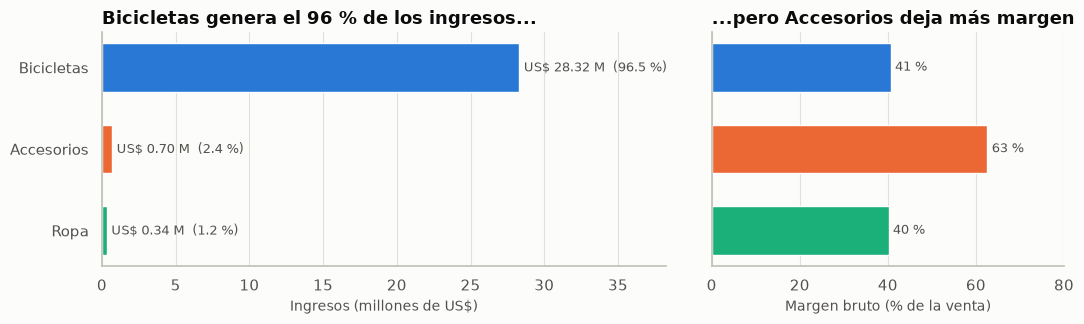

In [51]:
datos = por_categoria.sort_values("ingresos")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
colores = [COLOR_CATEGORIA[c] for c in datos.index]
ax1.barh(datos.index.astype(str), datos["ingresos"] / 1e6, color=colores, height=0.6)
for y, (ingreso, pct) in enumerate(zip(datos["ingresos"], datos["participacion_%"])):
    ax1.text(ingreso / 1e6 + 0.3, y, f"{millones(ingreso)}  ({pct:.1f} %)", va="center", color=TINTA_2, fontsize=9)
ax1.set_xlabel("Ingresos (millones de US$)")
ax1.margins(x=0.35)
ax1.set_title(f"Bicicletas genera el {datos.loc['Bicicletas', 'participacion_%']:.0f} % de los ingresos...")

ax2.barh(datos.index.astype(str), datos["margen_%"], color=colores, height=0.6)
for y, valor in enumerate(datos["margen_%"]):
    ax2.text(valor + 1, y, f"{valor:.0f} %", va="center", color=TINTA_2, fontsize=9)
ax2.set_xlabel("Margen bruto (% de la venta)")
ax2.set_xlim(0, 80)
ax2.set_title("...pero Accesorios deja más margen")
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "01_ingresos_margen_por_categoria")

**Interpretación.** La venta online es, en la práctica, un negocio de bicicletas: 96 de cada 100 dólares vienen de ellas. Los accesorios dejan 63 centavos de margen por dólar, frente a 41 de las bicicletas, pero su volumen es tan bajo que no compensan. La oportunidad no es reemplazar bicicletas por accesorios, sino **venderlos juntos**: cada accesorio que se suma a un pedido con bicicleta agrega margen alto sin costo de conseguir un cliente nuevo.

### 6.2 Evolución mensual de los ingresos y los pedidos (P2)

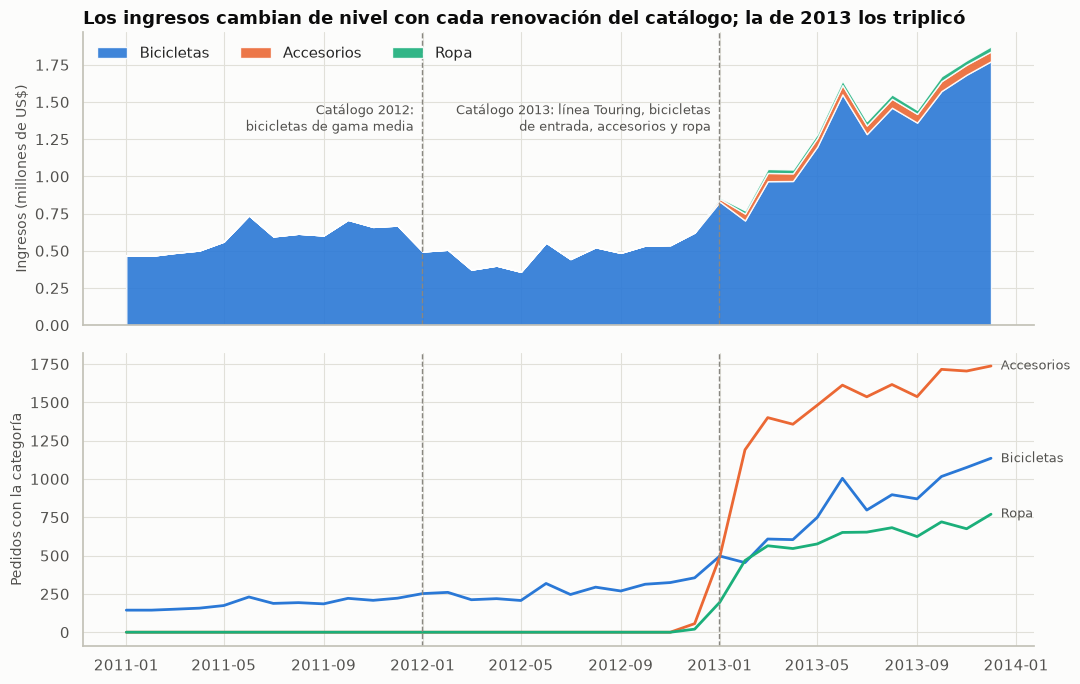

In [52]:
# Antes del lanzamiento de accesorios y ropa no hay ventas de esas categorías: 0, no vacío
mensual = completos.pivot_table(index="mes", columns="categoria", values="venta", aggfunc="sum", observed=True).fillna(0)
pedidos_mes = completos.groupby(["mes", "categoria"], observed=True)["pedido"].nunique().unstack().fillna(0)
x = mensual.index.to_timestamp()
# Meses en que empiezan a venderse modelos nuevos (renovaciones del catálogo)
inicio_modelos = ventas.groupby("modelo", observed=True)["fecha_pedido"].min()
renovaciones = sorted(inicio_modelos[inicio_modelos > ventas["fecha_pedido"].min()].dt.to_period("M").unique())
NOTAS = ["Catálogo 2012:\nbicicletas de gama media", "Catálogo 2013: línea Touring, bicicletas\nde entrada, accesorios y ropa"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.stackplot(x, [mensual[c] / 1e6 for c in COLOR_CATEGORIA], colors=list(COLOR_CATEGORIA.values()),
              labels=list(COLOR_CATEGORIA), alpha=0.9)
ax1.set_ylabel("Ingresos (millones de US$)")
ax1.legend(loc="upper left", ncol=3)
ax1.set_title("Los ingresos cambian de nivel con cada renovación del catálogo; la de 2013 los triplicó")

for categoria, color in COLOR_CATEGORIA.items():
    ax2.plot(x, pedidos_mes[categoria], color=color, lw=2, label=categoria)
    ax2.text(x[-1] + pd.Timedelta(days=12), pedidos_mes[categoria].iat[-1], categoria, color=TINTA_2, fontsize=9,
             va="center")
for renovacion, nota in zip(renovaciones, NOTAS):
    inicio = renovacion.end_time.normalize()
    for ax in (ax1, ax2):
        ax.axvline(inicio, color=TENUE, ls="--", lw=1)
    ax1.text(inicio - pd.Timedelta(days=10), 1.5, nota, ha="right", va="top", color=TINTA_2, fontsize=9)
ax2.set_ylabel("Pedidos con la categoría")
fig.tight_layout()
guardar(fig, "02_evolucion_mensual")

**Interpretación.** Los cambios de nivel coinciden con las dos renovaciones del catálogo. Con el catálogo de 2012, de gama media, los ingresos bajaron aunque los pedidos subieron. Con el de 2013, los pedidos se multiplicaron: los de accesorios pasaron de 0 a unos 1 700 al mes y los de bicicletas de unos 300 a 1 100. El crecimiento de ingresos de 2013 viene **sobre todo de vender más bicicletas**, no de los accesorios en sí. La coincidencia en el tiempo no prueba que una cosa cause la otra, pero indica que ampliar el catálogo (más gamas de precio y productos de entrada) atrajo tráfico que también compró bicicletas.

### 6.3 Estacionalidad: ingresos por mes y año (heatmap)

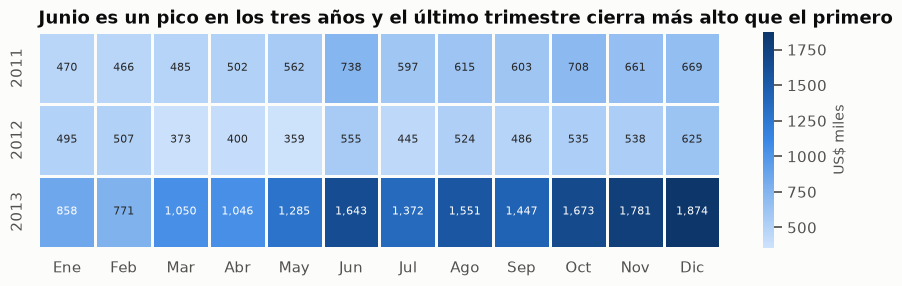

In [53]:
estacional = completos.pivot_table(index="anio", columns="nombre_mes", values="venta", aggfunc="sum", observed=True) / 1e3
fig, ax = plt.subplots(figsize=(11, 2.8))
sns.heatmap(estacional, cmap=SECUENCIAL, annot=True, fmt=",.0f", annot_kws={"fontsize": 8}, linewidths=2,
            linecolor=FONDO, cbar_kws={"label": "US$ miles"}, ax=ax)
ax.grid(False)
mejor = estacional.idxmax(axis=1)
ax.set_title("Junio es un pico en los tres años y el último trimestre cierra más alto que el primero")
ax.set_xlabel("")
ax.set_ylabel("")
guardar(fig, "03_estacionalidad")

**Interpretación.** En los tres años hay un **pico en junio** y los ingresos suben hacia fin de año. Enero a mayo es la temporada baja; su punto más bajo fue marzo a mayo de 2012. En 2013 el patrón se suma al crecimiento por el nuevo catálogo, así que cada mes supera al del año anterior. Para planificar: reforzar el stock de bicicletas antes de junio y del último trimestre, y usar la temporada baja para promociones que muevan inventario.

### 6.4 Distribución del importe por pedido y de la edad (histogramas)

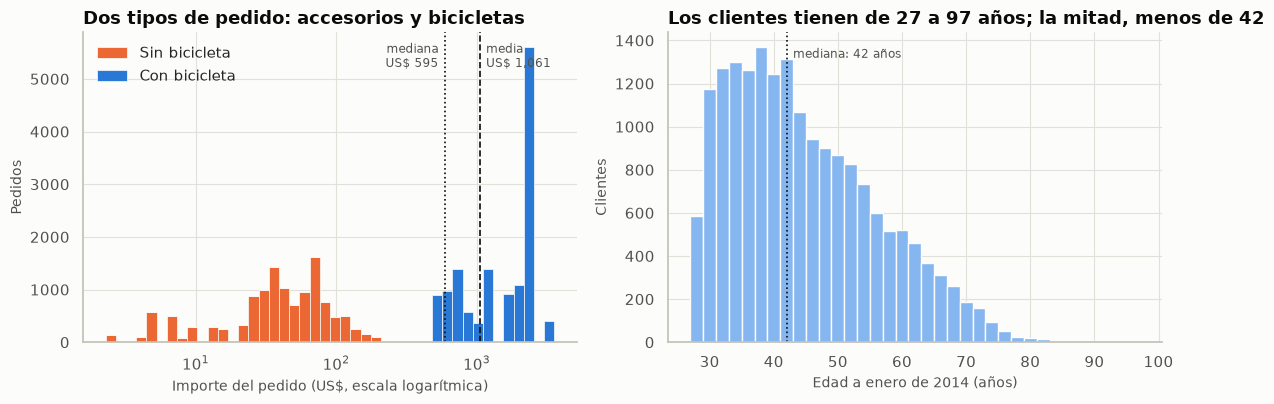

In [54]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

importe = pedidos["venta_pedido"]
bins = np.logspace(np.log10(importe.min()), np.log10(importe.max()), 45)
ax1.hist([importe[~pedidos["pedido_con_bicicleta"]], importe[pedidos["pedido_con_bicicleta"]]], bins=bins,
         stacked=True, color=[COLOR_CATEGORIA["Accesorios"], COLOR_CATEGORIA["Bicicletas"]],
         label=["Sin bicicleta", "Con bicicleta"], edgecolor=FONDO, linewidth=0.5)
ax1.set_xscale("log")
for valor, nombre, lado in [(importe.mean(), "media", "left"), (importe.median(), "mediana", "right")]:
    ax1.axvline(valor, color=TINTA, ls="--" if nombre == "media" else ":", lw=1.2)
    ax1.text(valor * (1.1 if lado == "left" else 0.9), ax1.get_ylim()[1] * 0.97, f"{nombre}\nUS$ {valor:,.0f}",
             color=TINTA_2, fontsize=8.5, va="top", ha=lado)
ax1.set_title("Dos tipos de pedido: accesorios y bicicletas")
ax1.set_xlabel("Importe del pedido (US$, escala logarítmica)")
ax1.set_ylabel("Pedidos")
ax1.legend(loc="upper left")

edad = clientes["edad"]
ax2.hist(edad, bins=range(edad.min(), edad.max() + 2, 2), color=AZUL_CLARO, edgecolor=FONDO)
ax2.axvline(edad.median(), color=TINTA, ls=":", lw=1.2)
ax2.text(edad.median() + 1, ax2.get_ylim()[1] * 0.95, f"mediana: {edad.median():.0f} años", color=TINTA_2,
         fontsize=8.5, va="top")
ax2.set_title("Los clientes tienen de 27 a 97 años; la mitad, menos de " f"{edad.median():.0f}")
ax2.set_xlabel("Edad a enero de 2014 (años)")
ax2.set_ylabel("Clientes")
fig.tight_layout()
guardar(fig, "04_histogramas_pedido_edad")

**Interpretación.** El importe por pedido no tiene forma de campana, sino **dos grupos separados**: los pedidos sin bicicleta (de US$ 2 a US$ 200) y los pedidos con bicicleta (más de US$ 500). Ni la media (US$ 1 061) ni la mediana (US$ 595) describen un pedido típico, porque caen en el hueco entre los dos grupos. Por eso los KPI de ticket deben calcularse por tipo de pedido. La edad se concentra entre 30 y 45 años, con una cola larga hacia edades mayores (mediana de 42 años).

### 6.5 Ingresos y gasto por cliente según el país (P3)

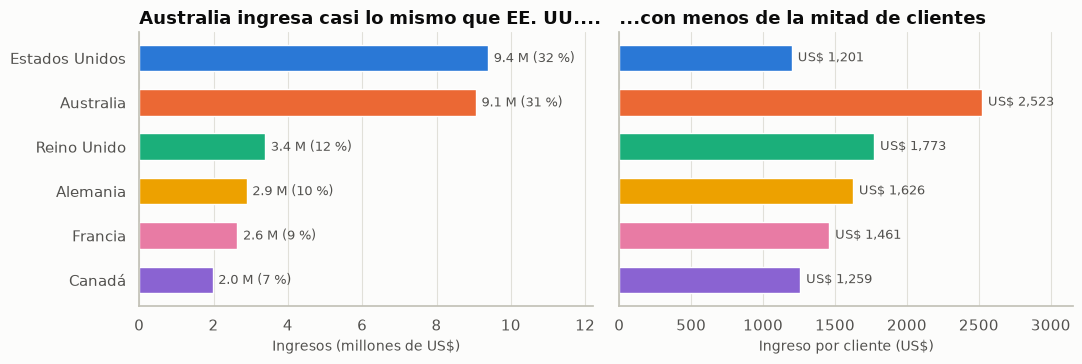

In [55]:
datos = por_pais.sort_values("ingresos")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
colores = [COLOR_PAIS[p] for p in datos.index]
ax1.barh(datos.index.astype(str), datos["ingresos"] / 1e6, color=colores, height=0.6)
for y, (valor, pct) in enumerate(zip(datos["ingresos"], datos["participacion_%"])):
    ax1.text(valor / 1e6 + 0.15, y, f"{valor / 1e6:,.1f} M ({pct:.0f} %)", va="center", color=TINTA_2, fontsize=9)
ax1.set_xlabel("Ingresos (millones de US$)")
ax1.margins(x=0.3)
ax1.set_title("Australia ingresa casi lo mismo que EE. UU....")

ax2.barh(datos.index.astype(str), datos["ingreso_por_cliente"], color=colores, height=0.6)
for y, valor in enumerate(datos["ingreso_por_cliente"]):
    ax2.text(valor + 40, y, f"US$ {valor:,.0f}", va="center", color=TINTA_2, fontsize=9)
ax2.set_xlabel("Ingreso por cliente (US$)")
ax2.margins(x=0.25)
ax2.set_title("...con menos de la mitad de clientes")
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "05_paises")

**Interpretación.** Australia genera casi los mismos ingresos que Estados Unidos con menos de la mitad de clientes: cada cliente australiano vale US$ 2 523, el doble que uno estadounidense (US$ 1 201). Reino Unido es el segundo mercado en valor por cliente. Canadá es el mercado más chico y uno de los de menor valor por cliente. Medir solo el número de clientes subestimaría a Australia y sobreestimaría a Estados Unidos.

### 6.6 Gasto por cliente según el país (boxplot)

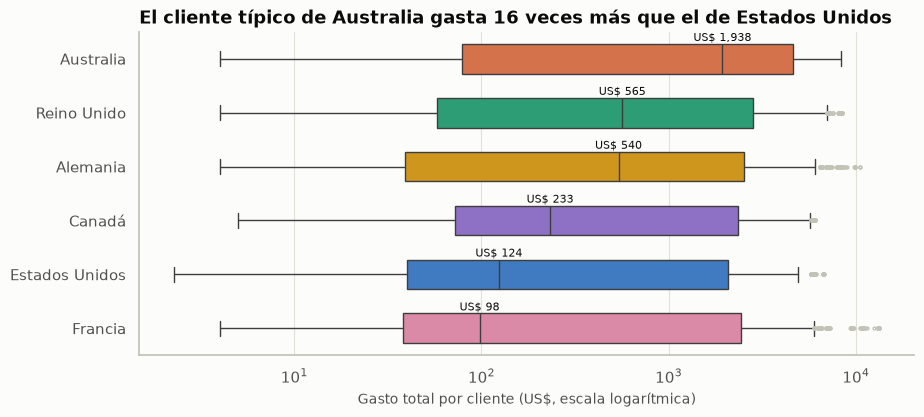

In [56]:
orden = clientes.groupby("pais", observed=True)["gasto_total"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.boxplot(data=clientes, x="gasto_total", y="pais", order=orden, hue="pais", palette=COLOR_PAIS, legend=False,
            dodge=False, width=0.55, fliersize=2, linewidth=1, flierprops={"markeredgecolor": GRIS}, ax=ax)
for y, pais_ in enumerate(orden):
    mediana = clientes.loc[clientes["pais"].eq(pais_), "gasto_total"].median()
    ax.text(mediana, y - 0.33, f"US$ {mediana:,.0f}", ha="center", fontsize=8, color=TINTA)
ax.set_xscale("log")
medianas = clientes.groupby("pais", observed=True)["gasto_total"].median()
ax.set_title(f"El cliente típico de Australia gasta {medianas['Australia'] / medianas['Estados Unidos']:.0f} veces "
             f"más que el de Estados Unidos")
ax.set_xlabel("Gasto total por cliente (US$, escala logarítmica)")
ax.set_ylabel("")
guardar(fig, "06_boxplot_gasto_pais")

**Interpretación.** El cliente típico (la mediana) es muy distinto según el país: US$ 1 938 en Australia frente a US$ 124 en Estados Unidos y US$ 98 en Francia. La razón es la compra de bicicletas: el 60 % de los clientes de Australia compró una, frente al 45-46 % en Estados Unidos y Francia y el 42 % en Canadá. En esos mercados, más de la mitad de los clientes solo compró accesorios. Ahí la oportunidad es **convertir a quienes compran accesorios en compradores de bicicleta**.

### 6.7 Precio y unidades vendidas por producto (scatterplot)

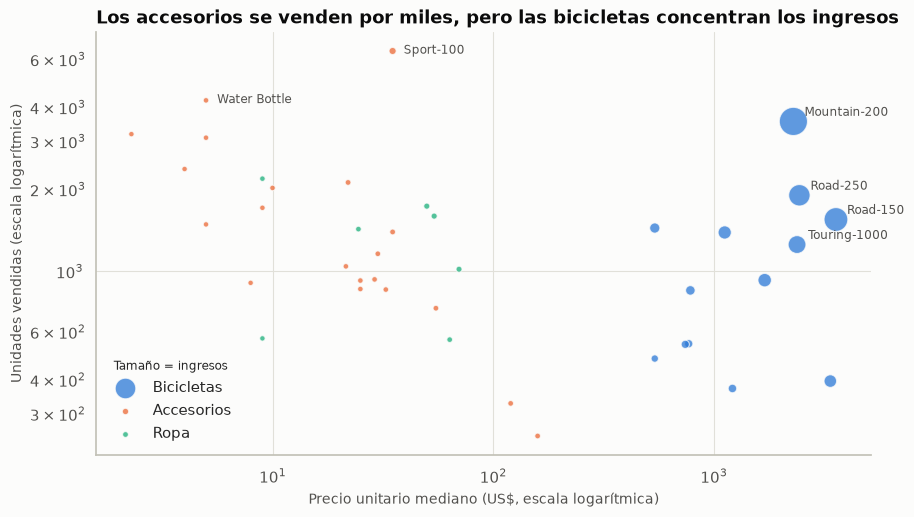

In [57]:
catalogo = ventas.groupby("modelo", observed=True).agg(
    precio=("precio_unitario", "median"), unidades=("cantidad", "sum"), ingresos=("venta", "sum"),
    categoria=("categoria", "first"))
fig, ax = plt.subplots(figsize=(10, 5.5))
for categoria, color in COLOR_CATEGORIA.items():
    grupo = catalogo[catalogo["categoria"].eq(categoria)]
    ax.scatter(grupo["precio"], grupo["unidades"], s=grupo["ingresos"] / 2e4 + 15, color=color, alpha=0.75,
               edgecolor=FONDO, linewidth=0.8, label=categoria)
for modelo, fila in catalogo.nlargest(4, "ingresos").iterrows():
    ax.annotate(modelo, (fila["precio"], fila["unidades"]), xytext=(8, 4), textcoords="offset points", fontsize=8.5,
                color=TINTA_2)
for modelo, fila in catalogo.nlargest(2, "unidades").iterrows():
    ax.annotate(modelo, (fila["precio"], fila["unidades"]), xytext=(8, -2), textcoords="offset points", fontsize=8.5,
                color=TINTA_2)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Precio unitario mediano (US$, escala logarítmica)")
ax.set_ylabel("Unidades vendidas (escala logarítmica)")
ax.set_title("Los accesorios se venden por miles, pero las bicicletas concentran los ingresos")
ax.legend(loc="lower left", title="Tamaño = ingresos", title_fontsize=8.5)
guardar(fig, "07_scatter_precio_unidades")

**Interpretación.** Los accesorios venden miles de unidades a menos de US$ 100 (6 000 cascos Sport-100, 4 000 botellas), pero sus burbujas son pequeñas. Las bicicletas venden de 400 a 3 500 unidades a precios de US$ 540 a US$ 3 600 y concentran los ingresos. Mountain-200 es el mejor producto: precio alto y el mayor volumen entre las bicicletas. No hay productos entre US$ 100 y US$ 500: es un **hueco en el catálogo** donde podrían entrar mejoras o componentes para quienes ya tienen bicicleta.

### 6.8 Correlaciones entre variables del cliente (heatmap)

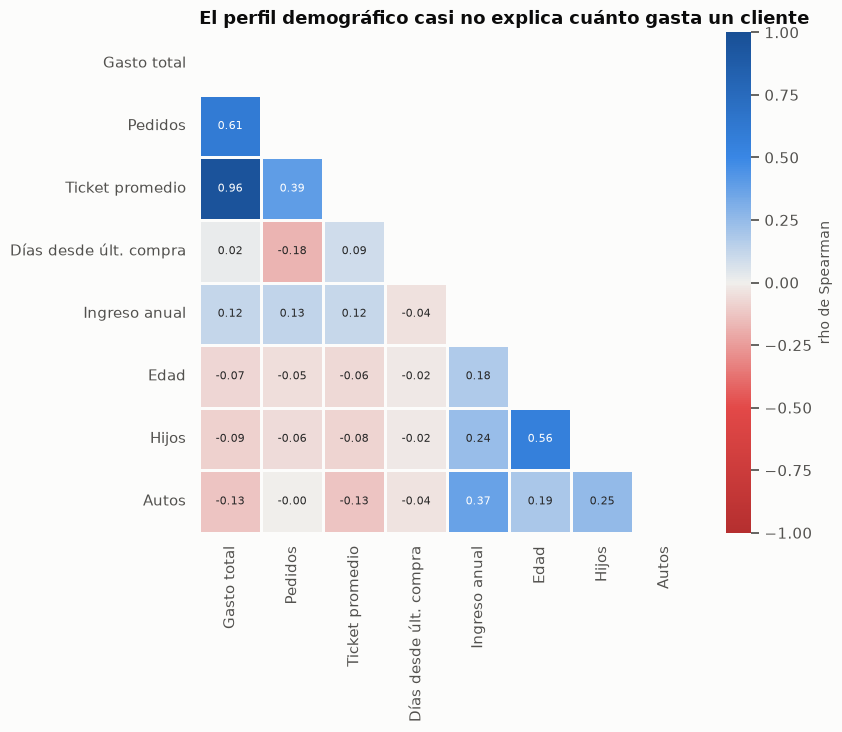

In [58]:
ETIQUETAS = {"gasto_total": "Gasto total", "pedidos": "Pedidos", "ticket_promedio": "Ticket promedio",
             "recencia_dias": "Días desde últ. compra", "ingreso_anual": "Ingreso anual", "edad": "Edad",
             "hijos": "Hijos", "autos": "Autos"}
matriz = spearman.rename(index=ETIQUETAS, columns=ETIQUETAS)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(matriz, mask=np.triu(np.ones(matriz.shape, dtype=bool)), cmap=DIVERGENTE, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"fontsize": 8}, linewidths=2, linecolor=FONDO,
            cbar_kws={"label": "rho de Spearman"}, ax=ax)
ax.grid(False)
ax.set_title("El perfil demográfico casi no explica cuánto gasta un cliente")
guardar(fig, "08_heatmap_correlaciones")

**Interpretación.** Lo que explica el gasto total es el comportamiento de compra: el ticket promedio (rho = 0,96) y el número de pedidos (0,61). Las variables demográficas casi no se relacionan con el gasto (|rho| ≤ 0,13); solo se relacionan entre sí (edad con hijos e ingreso con autos). Para segmentar clientes conviene usar su comportamiento (qué compran y con qué frecuencia) más que el perfil demográfico. Aun así, el perfil sí ayuda a saber **quién es más probable que compre una bicicleta** (6.9).

### 6.9 Quién compra bicicletas: autos e hijos (P4)

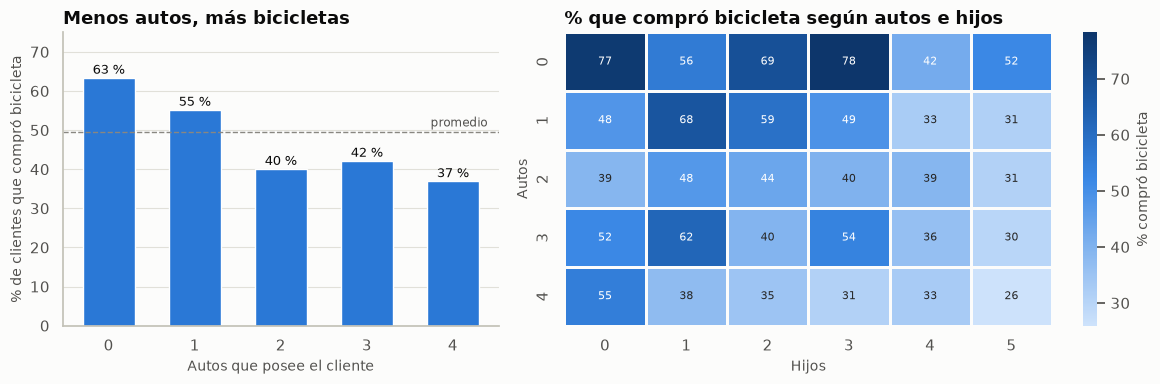

In [59]:
bici = clientes.pivot_table(index="autos", columns="hijos", values="compro_bicicleta", aggfunc="mean") * 100
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
por_autos = perfil("autos")
ax1.bar(por_autos.index.astype(str), por_autos["compro_bicicleta_pct"], color=AZUL, width=0.6)
for x_, valor in enumerate(por_autos["compro_bicicleta_pct"]):
    ax1.text(x_, valor + 1, f"{valor:.0f} %", ha="center", fontsize=9, color=TINTA)
ax1.axhline(clientes["compro_bicicleta"].mean() * 100, color=TENUE, ls="--", lw=1)
ax1.text(4.4, clientes["compro_bicicleta"].mean() * 100 + 1.5, "promedio", color=TINTA_2, fontsize=8.5, ha="right")
ax1.set_xlabel("Autos que posee el cliente")
ax1.set_ylabel("% de clientes que compró bicicleta")
ax1.set_ylim(0, 75)
ax1.grid(axis="x", visible=False)
ax1.set_title("Menos autos, más bicicletas")

sns.heatmap(bici, cmap=SECUENCIAL, annot=True, fmt=".0f", annot_kws={"fontsize": 8}, linewidths=2, linecolor=FONDO,
            cbar_kws={"label": "% compró bicicleta"}, ax=ax2)
ax2.grid(False)
ax2.set_xlabel("Hijos")
ax2.set_ylabel("Autos")
ax2.set_title("% que compró bicicleta según autos e hijos")
fig.tight_layout()
guardar(fig, "09_compra_bicicleta_perfil")

**Interpretación.** Tener menos autos es el rasgo que más se asocia a comprar una bicicleta: el 63 % de los clientes sin auto compró una, frente al 37 % de los que tienen 4. El heatmap muestra que los porcentajes más altos están en la fila de 0 autos (69-78 %) y los más bajos en las familias con muchos autos y muchos hijos (26-33 %). La bicicleta parece ser un **medio de transporte**, no solo un deporte. Por eso las campañas de bicicletas deberían dirigirse a clientes con 0 o 1 auto, pocos hijos y que viven cerca del trabajo. Las celdas con pocos clientes (por ejemplo, 0 autos y 3 hijos) deben leerse con cuidado.

### 6.10 Razones de compra declaradas (P5)

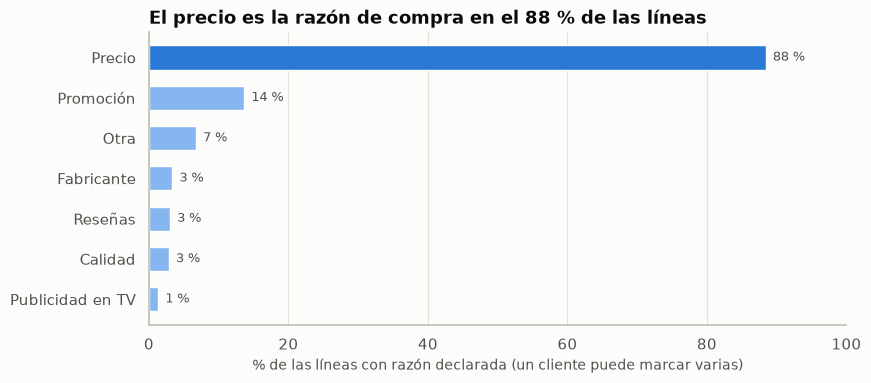

In [60]:
razones_pct = (con_razon[COLUMNAS_RAZON].mean() * 100).sort_values()
etiquetas = {f"razon_{v}": v.replace("_", " ").capitalize() for v in RAZONES.values()}
etiquetas.update({"razon_resenas": "Reseñas", "razon_promocion": "Promoción", "razon_publicidad_tv": "Publicidad en TV"})
fig, ax = plt.subplots(figsize=(9, 3.8))
colores = [AZUL if r == razones_pct.idxmax() else AZUL_CLARO for r in razones_pct.index]
ax.barh(razones_pct.index.map(etiquetas), razones_pct, color=colores, height=0.6)
for y, valor in enumerate(razones_pct):
    ax.text(valor + 1, y, f"{valor:.0f} %", va="center", fontsize=9, color=TINTA_2)
ax.set_xlabel("% de las líneas con razón declarada (un cliente puede marcar varias)")
ax.set_title(f"El precio es la razón de compra en el {razones_pct.max():.0f} % de las líneas")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
guardar(fig, "10_razones_compra")

**Interpretación.** El precio es la razón de compra en el 88 % de las líneas. La promoción aparece en el 14 % y la publicidad en televisión solo en el 1 %. En las bicicletas pesan más la promoción, el fabricante y la calidad. Para la estrategia: competir en precio en accesorios y ropa; en bicicletas, comunicar la marca y la calidad y usar promociones. La inversión en televisión no muestra efecto en las compras declaradas.

### 6.11 Aporte de cada segmento de clientes (P6)

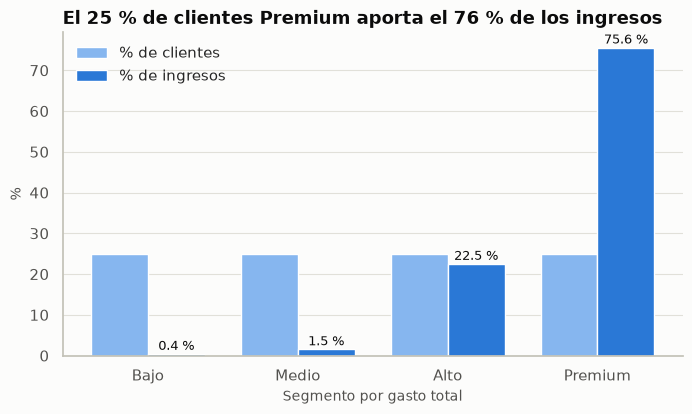

In [61]:
fig, ax = plt.subplots(figsize=(8, 4.2))
posiciones = np.arange(len(por_segmento))
ancho = 0.38
ax.bar(posiciones - ancho / 2, por_segmento["clientes_%"], ancho, color=AZUL_CLARO, label="% de clientes")
ax.bar(posiciones + ancho / 2, por_segmento["ingresos_%"], ancho, color=AZUL, label="% de ingresos")
for x_, valor in zip(posiciones + ancho / 2, por_segmento["ingresos_%"]):
    ax.text(x_, valor + 1, f"{valor:.1f} %", ha="center", fontsize=9, color=TINTA)
ax.set_xticks(posiciones, por_segmento.index.astype(str))
ax.set_title(f"El 25 % de clientes Premium aporta el {por_segmento['ingresos_%'].iat[-1]:.0f} % de los ingresos")
ax.set_ylabel("%")
ax.set_xlabel("Segmento por gasto total")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
guardar(fig, "11_segmentos_clientes")

**Interpretación.** La mitad de los clientes (Alto y Premium) genera el 98 % de los ingresos, y la otra mitad, el 1,9 %. El salto entre segmentos es comprar una bicicleta: ningún cliente Bajo o Medio la compró, y el 100 % de los Premium sí. Además, el 93 % de los Premium vuelve a comprar. Hay dos palancas: **retener a los Premium**, que son pocos y valen mucho, y **convertir a los clientes de accesorios** (Bajo y Medio) en compradores de su primera bicicleta.

### 6.12 Fotos de los productos con más ingresos (dato no estructurado)

Con los cálculos terminados, se piden a la base **solo las fotos que interesan**: la del producto con más ingresos de cada categoría. Es el uso del dato no estructurado clasificado en 2.5: la imagen no entra en los KPI, pero ayuda a comunicar qué se vende.

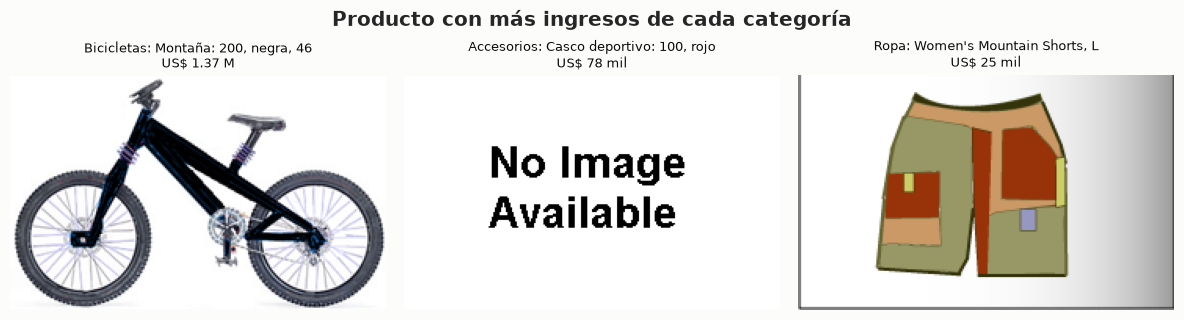

In [62]:
# Producto con más ingresos de cada categoría (sumando todas sus versiones)
lideres = (ventas.groupby(["categoria", "id_producto", "producto"], observed=True)["venta"].sum().reset_index()
           .sort_values("venta", ascending=False).drop_duplicates("categoria"))
lideres["archivo"] = (lideres["producto"].str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
                      .str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_") + ".gif")

# Solo se descargan esas fotos; sin conexión se usan las que ya están en datos/imagenes/
if HAY_BD:
    from sqlalchemy import text

    for anterior in IMAGENES.glob("*.gif"):
        anterior.unlink()
    with motor_sql().connect() as con:
        for _, fila in lideres.iterrows():
            foto = con.execute(text("SELECT TOP 1 LargePhoto FROM dbo.DimProduct WHERE ProductAlternateKey = :clave"),
                               {"clave": fila["id_producto"]}).scalar_one()
            (IMAGENES / fila["archivo"]).write_bytes(foto)

fig, ejes = plt.subplots(1, len(lideres), figsize=(12, 3.4))
for ax, (_, fila) in zip(ejes, lideres.iterrows()):
    ax.imshow(Image.open(IMAGENES / fila["archivo"]).convert("RGB"))
    monto = millones(fila["venta"]) if fila["venta"] >= 1e6 else f"US$ {fila['venta'] / 1e3:,.0f} mil"
    ax.set_title(f"{fila['categoria']}: {fila['producto']}\n{monto}", fontsize=9,
                 fontweight="normal", loc="center")
    ax.axis("off")
fig.suptitle("Producto con más ingresos de cada categoría", fontweight="bold")
fig.tight_layout()
guardar(fig, "12_productos_con_mas_ingresos")

**Interpretación.** La bicicleta Montaña-200 negra talla 46 es el producto que más ingresa (US$ 1,37 M sumando sus versiones). El accesorio con más ingresos, el casco deportivo Sport-100 rojo (US$ 78 mil), **no tiene foto en la base**: en su lugar está una imagen genérica *No Image Available*. Es una falla de calidad del catálogo que no afecta a los KPI, pero que conviene corregir antes de usar las fotos en la tienda online o en campañas: el producto estrella de su categoría se mostraría sin imagen.

## 7. Interpretación y hallazgos para Adventure Works Cycles

### 7.1 Calidad de los datos

Los datos de AdventureWorksDW son **exactos en montos y relaciones**: no hay duplicados ni claves sin correspondencia, y los importes y costos cuadran. Los problemas están en el formato (teléfonos en dos formatos, códigos postales sin espacio o truncados, tallas mezcladas, `Color = 'NA'`) y en atributos que el sistema registra mal: el 20 % de las ventas tiene una moneda que no es la de su país, el 3,6 % tiene una promoción que no se aplicó y el 47 % cae fuera de la vigencia del producto porque 200 versiones del catálogo terminan antes de empezar. Lo que se pudo corregir sin inventar datos se corrigió; lo demás quedó en `REPORTE_NO_CORREGIDOS.csv` con su valor original, y para el análisis se tomaron decisiones documentadas (montos en USD, precio y costo de la propia venta, meses incompletos fuera de las tendencias).

### 7.2 Principales hallazgos

1. **La venta online depende de las bicicletas.** Generan el 96,5 % de los ingresos (US$ 28,3 M de US$ 29,4 M). Tres modelos (Mountain-200, Road-150 y Road-250) generan el 61 %. Los accesorios tienen el mejor margen (63 %), pero aportan el 2,4 %.
2. **Cada renovación del catálogo cambió el negocio.** Pasar de gama alta a gama media en 2012 hizo caer los ingresos 17 %, aunque se vendieron más bicicletas. Ampliar el catálogo en 2013 (línea Touring, bicicletas de entrada, accesorios y ropa) multiplicó los pedidos por 6,5 y los ingresos crecieron 180 %.
3. **Australia es el mercado más valioso por cliente.** Genera casi lo mismo que Estados Unidos con menos de la mitad de clientes (US$ 2 523 frente a US$ 1 201 por cliente), porque el 60 % de sus clientes compra una bicicleta.
4. **Comprar una bicicleta define el valor del cliente.** La mitad de los clientes que compró al menos una genera el 98 % de los ingresos; ningún cliente de los segmentos Bajo y Medio compró una. Solo el 29 % de los clientes nuevos de 2013 lo hizo.
5. **Quién compra bicicletas:** clientes con menos autos (63 % sin auto frente a 37 % con 4), con pocos hijos, que viven cerca del trabajo, solteros y de 35 a 44 años. El ingreso aumenta el gasto, pero no la probabilidad de comprar una bicicleta.
6. **Se compra por precio; las promociones y la publicidad casi no influyen.** El precio es la razón en el 88 % de las líneas, la televisión en el 1 %, y el 96 % de las líneas no tiene promoción.
7. **Hay estacionalidad:** junio es un pico todos los años y el último trimestre cierra más alto que el primero.

### 7.3 Implicancias y decisiones para Adventure Works Cycles

| Hallazgo | Implicancia | Decisión propuesta |
|---|---|---|
| Bicicletas = 96,5 % de los ingresos; 3 modelos = 61 % | Un quiebre de stock o un problema con esos modelos golpea directamente los ingresos | Asegurar el stock de Mountain-200, Road-250 y Touring-1000; revisar el impacto en ingresos antes de reemplazar un modelo |
| Pasar a gama media bajó los ingresos; ampliar el catálogo los triplicó | Las decisiones de catálogo son las que más mueven las ventas | Ampliar el catálogo sumando gamas en lugar de reemplazarlas; cubrir el hueco de precios entre US$ 100 y US$ 500 |
| Accesorios: 63 % de margen, 2,4 % de los ingresos | Margen alto que hoy casi no se aprovecha | Ofrecer packs de bicicleta + casco, botella y cubiertas al momento de la compra |
| Australia: US$ 2 523 por cliente | Es el mercado donde cada cliente vale más | Priorizar la inversión comercial en Australia y Reino Unido; estudiar qué hace distinto el cliente australiano |
| Bajo y Medio nunca compran bicicleta | La mitad de los clientes aporta el 2 % de los ingresos | Campañas de primera bicicleta para quienes ya compraron accesorios, dirigidas al perfil con más probabilidad (pocos autos, pocos hijos, cerca del trabajo) |
| Premium: 75,6 % de los ingresos y 93 % de recompra | Perder clientes Premium cuesta tres cuartos del negocio | Programa de fidelización (mantenimiento, accesorios, cambio de bicicleta) con alertas cuando pasan muchos días sin comprar |
| Se compra por precio; TV en el 1 % | La publicidad en televisión no muestra efecto | Reasignar presupuesto de TV a precios competitivos y a promociones de bicicletas |
| Pico en junio y en el último trimestre | La demanda no es pareja en el año | Planificar el stock y las campañas según la estacionalidad |
| Moneda, promociones y vigencia mal registradas | Reportes por moneda, por promoción o por vigencia del catálogo darían resultados falsos | Corregir en el sistema de origen con `REPORTE_NO_CORREGIDOS.csv`: moneda según el país, promociones que apliquen el descuento y fechas de vigencia coherentes |

### 7.4 Siguientes pasos

Con los datos ya validados, la siguiente iteración de CRISP-DM puede pasar a modelos: clasificación de qué clientes de accesorios tienen más probabilidad de comprar una bicicleta, segmentación RFM con *k-means* y pronóstico de ventas mensuales que considere la estacionalidad y las renovaciones del catálogo.

## 8. Archivos generados

| Archivo | Contenido |
|---|---|
| `datos/SL/*.csv` | Copia de las tablas de SQL Server sin limpiar |
| `datos/imagenes/*.gif` | Fotos de los productos con más ingresos de cada categoría (sección 6.12), descargadas de la base |
| `datos/CL/ventas_CL.csv` | Dataset limpio e integrado: una fila por línea de pedido, con las variables derivadas |
| `reporte/REPORTE_NO_CORREGIDOS.csv` | Datos que no se pudieron corregir, con su tabla, clave, valor original y motivo |
| `graficos/*.png` | Gráficos de la sección 6 |